# Optiver — team EDA
1. In Google Drive, add a shortcut of the shared `Optiver_Project` folder to **My Drive**. Keep the same folder name.
2. Run setup cells **1–3** and allow Drive access. The data is already saved; no Kaggle download is needed.
3. Add your exploration and visualizations under your name below.

Rerun setup when starting a new Colab session.

## 1. Connect Google Drive

In [19]:
from pathlib import Path
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow
from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive/Optiver_Project/data")
LOCAL_DIR = Path("/content/optiver_data")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Access the saved data

In [20]:
def data_complete(folder):
    """Check labels, stock partitions, and the supplied test files."""
    try:
        if not all((folder / name).is_file() for name in
                   ["train.csv", "test.csv", "sample_submission.csv"]):
            return False
        labels = pd.read_csv(folder / "train.csv", usecols=["stock_id"])
        if labels.empty:
            return False
        for kind in ["book", "trade"]:
            for stock_id in labels.stock_id.unique():
                part = folder / f"{kind}_train.parquet" / f"stock_id={stock_id}"
                if not any(p.stat().st_size > 0 for p in part.rglob("*.parquet")):
                    return False
            if not any(p.stat().st_size > 0 for p in
                       (folder / f"{kind}_test.parquet").rglob("*.parquet")):
                return False
        return True
    except (OSError, ValueError, pd.errors.EmptyDataError):
        return False

if data_complete(DATA_DIR):
    print("Using the existing Google Drive copy. No download needed.")
else:
    if not data_complete(LOCAL_DIR):
        print("No complete saved copy found. Downloading from Kaggle once...")
        import kagglehub
        from google.colab import userdata
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            raise RuntimeError(
                "Add KAGGLE_API_TOKEN in Colab Secrets and enable notebook access. "
                "Teammates: first check that the shared Drive shortcut and DATA_DIR are correct."
            ) from None
        kagglehub.competition_download(
            "optiver-realized-volatility-prediction", output_dir=str(LOCAL_DIR)
        )
        if not data_complete(LOCAL_DIR):
            raise RuntimeError("The local download is incomplete. Check the download output.")
    print("Copying the downloaded files to Google Drive. Wait for completion...")
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(LOCAL_DIR, DATA_DIR, dirs_exist_ok=True)
    if not data_complete(DATA_DIR):
        raise RuntimeError("The Drive copy is incomplete. Check available Drive space and rerun.")

print("Data saved in Google Drive and ready:", DATA_DIR)

Using the existing Google Drive copy. No download needed.
Data saved in Google Drive and ready: /content/drive/MyDrive/Optiver_Project/data


## 3. Load data
`train` = all labels; `book` and `trades` = one stock. Change `STOCK_ID` to explore another stock.

In [21]:
train = pd.read_csv(DATA_DIR / "train.csv")
STOCK_ID = 0  # Change this to another stock_id from train.

def load_stock(kind, stock_id):
    folder = DATA_DIR / f"{kind}_train.parquet" / f"stock_id={stock_id}"
    paths = sorted(folder.rglob("*.parquet"))
    if not paths:
        raise ValueError(f"No {kind} data found for stock_id={stock_id}.")
    return pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True).sort_values(
        ["time_id", "seconds_in_bucket"]
    ).reset_index(drop=True)

book = load_stock("book", STOCK_ID)
trades = load_stock("trade", STOCK_ID)
print(f"Labels: {len(train):,} | Stocks: {train.stock_id.nunique()}")
print(f"Stock {STOCK_ID}: {len(book):,} book rows; {len(trades):,} trade rows")
display(train.head())
display(book.head())
display(trades.head())


Labels: 428,932 | Stocks: 112
Stock 0: 917,553 book rows; 123,443 trade rows


,stock_id,time_id,target
0,0,5,0.004136
1,0,11,0.001445
2,0,16,0.002168
3,0,31,0.002195
4,0,62,0.001747


,time_id,seconds_in_bucket,bid_price1,ask_price1,bid_price2,ask_price2,bid_size1,ask_size1,bid_size2,ask_size2
0,5,0,1.001422,1.002301,1.00137,1.002353,3,226,2,100
1,5,1,1.001422,1.002301,1.00137,1.002353,3,100,2,100
2,5,5,1.001422,1.002301,1.00137,1.002405,3,100,2,100
3,5,6,1.001422,1.002301,1.00137,1.002405,3,126,2,100
4,5,7,1.001422,1.002301,1.00137,1.002405,3,126,2,100


,time_id,seconds_in_bucket,price,size,order_count
0,5,21,1.002301,326,12
1,5,46,1.002778,128,4
2,5,50,1.002818,55,1
3,5,57,1.003155,121,5
4,5,68,1.003646,4,1


## Team visualizations
Add your code and notes under your name.

### Swarnendu

## Exploring the Training Data and Stock Coverage

We investigate the structure of the training dataset and verify that the stock and time identifiers are consistent across the order-book data, and trade data.

Since we are not predicting the volatility which was the original aim of the project, we don't use the `train.csv` file.

We inspect the `book_train.parquet` and `trade_train.parquet` directories to identify the stock IDs for which order-book and trade data are available.

This consistency check is important because the order-book and trade data will later be used to engineer predictive features. Matching stock IDs and time IDs across both the sources helps ensure proper feature engineering.

In [22]:

## which stocks and how many stocks appear in the training set
#train = pd.read_csv(DATA_DIR / "train.csv")
#print("Train file: \n", train.head())
#print("\n Train shape:", train.shape)
#print("\n Train file - unique stock ids:", train["stock_id"].unique())
#print("\n Train file - number of stock ids:", len(train["stock_id"].unique()))
#print("\n Train file - unique time ids: ", train["time_id"].unique())
#print("\n Train file - number of time ids:", len(train["time_id"].unique()))

## Are data for corresponding stock ids present for book and trade folders

book_st_id=[]
book_root= DATA_DIR/"book_train.parquet"
book_folders=book_root.glob("stock_id=*")
for folder in book_folders:
    if folder.is_dir():
      book_st_id.append(int(folder.name.split("=")[1]))

trade_st_id=[]
trade_root= DATA_DIR/"trade_train.parquet"
trade_folders=trade_root.glob("stock_id=*")
for folder in trade_folders:
    if folder.is_dir():
      trade_st_id.append(int(folder.name.split("=")[1]))

print("\n The number of stock ids in book_train folder:", len(book_st_id) )
print("\n The number of stock ids in trade_train folder:", len(trade_st_id) )

book_id=set(book_st_id)
trade_id=set(trade_st_id)
train_id=set(train["stock_id"])

print("\n Do all book_id matches with train_id?", train_id== book_id)
print("\n Do all book_id matches with train_id?", train_id== trade_id)

print("\n ")




 The number of stock ids in book_train folder: 112

 The number of stock ids in trade_train folder: 112

 Do all book_id matches with train_id? True

 Do all book_id matches with train_id? True

 


## Defining the Target: Final Mid-Price

The objective is to predict final mid-price of each 10-minute observation window, using order-book and trade information available up to 540 seconds (9 minutes).

The mid-price is defined as the average of the best ask price and the best bid price:

$\mathrm{mid-price}_t = \displaystyle \frac{\text{best ask-price}_t + \text{best bid-price}_t}{2}.$

For each `time_id`, we calculate the target final mid-price which will be later used for both training and test set:

- **$\mathrm{mid-price}_{540}$**: Mid-price at 540 seconds (9th min).
- **$\mathrm{mid-price}_{last}$**: Final mid-price at 600 seconds (10 min). **This is the target.**
- **$\mathrm{mid-price}_{relchange}$**: The relative mid-price change between these two observations: $\frac{m_{\mathrm{last}} - m_{540}}{m_{540}}.$

If no order book data is available after 540 seconds, we set the final mid-price as NAN. The variables **$\mathrm{mid-price}_{last}$** and **$\mathrm{mid-price}_{relchange}$** are not used in present model but are calculated for future modelling excercises.

In [59]:
def calculate_target_midprices(g):
    t = g["seconds_in_bucket"].to_numpy()
    p = g["MidPrice"].to_numpy()

    # Last mid-price at or before 540 seconds
    i300 = np.searchsorted(t, 300, side="right") - 1

    # Last available mid-price at or before 600 seconds
    iend = np.searchsorted(t, 600, side="right") - 1

    # Require a starting price and a final-minute observation
    if i300 < 0 or iend < 0 or t[iend] <= 300:
      return pd.Series({"midprice_300": np.nan, "midprice_last": np.nan, "midprice_relchange": np.nan})

    m300 = p[i300]
    mend = p[iend]

    if m300 <= 0 or mend <= 0:
      return pd.Series({"midprice_300": m300, "midprice_last": mend, "midprice_relchange": np.nan})

    return pd.Series({"midprice_300": m300, "midprice_last": mend, "midprice_relchange": (mend - m300) / m300})

def engineer_target(st_id, diagnostics=False):

    # Load order-book data for one stock
    df = load_stock("book", st_id).copy()

    # Sort snapshots within each time window
    df = df.sort_values(["time_id", "seconds_in_bucket"]).copy()

    df["MidPrice"] = (df["ask_price1"] + df["bid_price1"]) / 2

    targets = (df.groupby("time_id").apply(calculate_target_midprices, include_groups=False).reset_index())
    targets["stock_id"] = st_id
    targets = targets[["stock_id", "time_id", "midprice_300", "midprice_last", "midprice_relchange"]]


    if diagnostics:
        print(f"Stock ID: {st_id}")
        print("Book shape:", df.shape)
        print("Number of time IDs:", df["time_id"].nunique())
        print("Missing values:\n", df.isnull().sum())

    return targets

stock_ids=np.sort(book_st_id)
all_targets=[]

for st_id in stock_ids:
    print(f"Processing stock {st_id}")
    targets = engineer_target(st_id=st_id, diagnostics=False)
    all_targets.append(targets)

Y = pd.concat(all_targets, ignore_index=True)

print("Target matrix shape:", Y.shape)
print("Number of stocks:", Y["stock_id"].nunique())
print("Number of stock/time_id rows:", Y[["stock_id", "time_id"]].drop_duplicates().shape[0])

display(Y.head())

Processing stock 0
Processing stock 1
Processing stock 2
Processing stock 3
Processing stock 4
Processing stock 5
Processing stock 6
Processing stock 7
Processing stock 8
Processing stock 9
Processing stock 10
Processing stock 11
Processing stock 13
Processing stock 14
Processing stock 15
Processing stock 16
Processing stock 17
Processing stock 18
Processing stock 19
Processing stock 20
Processing stock 21
Processing stock 22
Processing stock 23
Processing stock 26
Processing stock 27
Processing stock 28
Processing stock 29
Processing stock 30
Processing stock 31
Processing stock 32
Processing stock 33
Processing stock 34
Processing stock 35
Processing stock 36
Processing stock 37
Processing stock 38
Processing stock 39
Processing stock 40
Processing stock 41
Processing stock 42
Processing stock 43
Processing stock 44
Processing stock 46
Processing stock 47
Processing stock 48
Processing stock 50
Processing stock 51
Processing stock 52
Processing stock 53
Processing stock 55
Processing

,stock_id,time_id,midprice_300,midprice_last,midprice_relchange
0,0,5,1.004137,1.003439,-0.000695
1,0,11,1.000276,1.000527,0.000251
2,0,16,0.999952,0.997798,-0.002154
3,0,31,0.998381,0.997941,-0.000440
4,0,62,0.999534,0.999930,0.000396


# Order Book and Trade Activity Visualization

Visualize order-book and trade data for a selected stock and `time_id` over a 10-minute window.

## Data

**Order-book data:** Best and second-best bid/ask prices and sizes (`bid_price1`, `ask_price1`, `bid_size1`, `ask_size1`, etc.).

**Trade data:** Executed price, trade size, and order count.


## Visualization

1. **Price dynamics:** Bid/ask prices at Levels 1 and 2, mid-price, trade prices, and final observed mid-price.
2. **Order-book depth:** Bid and ask sizes at the first two price levels.
3. **Trade activity:** Trade size and order count.

The vertical line at 540 seconds marks the prediction cutoff.

- **0–540 seconds:** Model input period.
- **540–600 seconds:** Prediction horizon.
- **Final observed mid-price:** Forecasting target.

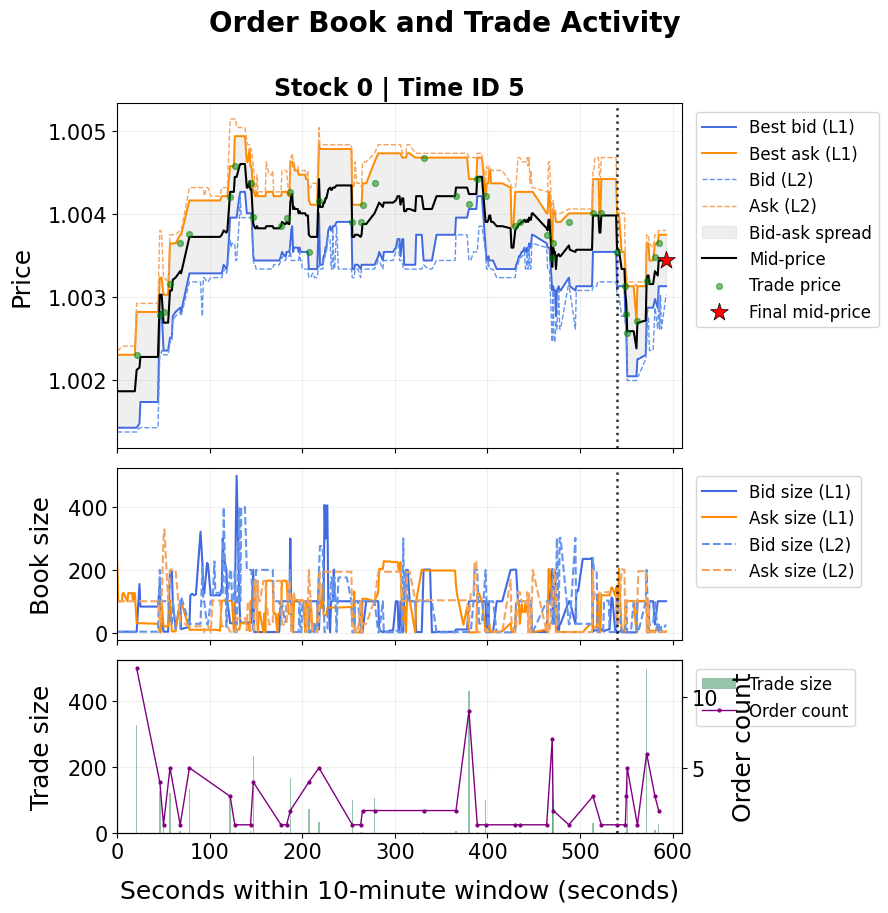

In [60]:


# ==========================================
# 1. LOAD AND PREPARE DATA
# ==========================================

st_id = 0
tid = 5

book = load_stock("book", st_id).copy()
trade = load_stock("trade", st_id).copy()

# Select the required time_id
book = book[book["time_id"] == tid].copy()
trade = trade[trade["time_id"] == tid].copy()

# Sort observations by time
book = book.sort_values("seconds_in_bucket").reset_index(drop=True)
trade = trade.sort_values("seconds_in_bucket").reset_index(drop=True)

# Keep observations up to 600 seconds
book = book[book["seconds_in_bucket"] <= 600].copy()
trade = trade[trade["seconds_in_bucket"] <= 600].copy()

# Calculate mid-price
book["MidPrice"] = (book["ask_price1"] + book["bid_price1"]) / 2

# Check whether order-book data exist
if book.empty:
    raise ValueError(f"No order-book data for stock {st_id}, time_id {tid}")

# Final observed mid-price
final_price = book["MidPrice"].iloc[-1]
final_time = book["seconds_in_bucket"].iloc[-1]

# ==========================================
# 2. CREATE FIGURE
# ==========================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(9, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1.5, 1.5]}
)

ax1, ax2, ax3 = axes
t = book["seconds_in_bucket"]

# ==========================================
# 3. PRICE PANEL
# ==========================================

ax1.plot(t, book["bid_price1"], color="royalblue",
         linewidth=1.4, label="Best bid (L1)")

ax1.plot(t, book["ask_price1"], color="darkorange",
         linewidth=1.4, label="Best ask (L1)")

ax1.plot(t, book["bid_price2"], color="cornflowerblue",
         linestyle="--", linewidth=1, label="Bid (L2)")

ax1.plot(t, book["ask_price2"], color="sandybrown",
         linestyle="--", linewidth=1, label="Ask (L2)")

ax1.fill_between(
    t,
    book["bid_price1"],
    book["ask_price1"],
    color="grey",
    alpha=0.12,
    label="Bid-ask spread"
)

ax1.plot(t, book["MidPrice"], color="black",
         linewidth=1.5, label="Mid-price")

if not trade.empty and "price" in trade.columns:
    ax1.scatter(
        trade["seconds_in_bucket"],
        trade["price"],
        color="green",
        s=18,
        alpha=0.5,
        label="Trade price",
        zorder=4
    )

# Mark the final observed mid-price
ax1.scatter(
    final_time,
    final_price,
    color="red",
    marker="*",
    s=180,
    edgecolors="black",
    linewidths=0.5,
    label="Final mid-price",
    zorder=6
)

ax1.set_ylabel("Price", fontsize=18, labelpad=10)
ax1.set_title(
    f"Stock {st_id} | Time ID {tid}",
    fontsize=17,
    fontweight="bold"
)

ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=12)
ax1.grid(alpha=0.2)

# ==========================================
# 4. ORDER-BOOK SIZE PANEL
# ==========================================

ax2.plot(t, book["bid_size1"], color="royalblue",
         label="Bid size (L1)")

ax2.plot(t, book["ask_size1"], color="darkorange",
         label="Ask size (L1)")

ax2.plot(t, book["bid_size2"], color="cornflowerblue",
         linestyle="--", label="Bid size (L2)")

ax2.plot(t, book["ask_size2"], color="sandybrown",
         linestyle="--", label="Ask size (L2)")

ax2.set_ylabel("Book size", fontsize=18, labelpad=10)
ax2.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=12)
ax2.grid(alpha=0.2)

# ==========================================
# 5. TRADE ACTIVITY PANEL
# ==========================================

if not trade.empty:

    ax3.bar(
        trade["seconds_in_bucket"],
        trade["size"],
        width=1.5,
        color="seagreen",
        alpha=0.5,
        label="Trade size"
    )

    ax3.set_ylabel("Trade size", fontsize=18, labelpad=10)

    # Secondary y-axis for order count
    if "order_count" in trade.columns:

        ax3b = ax3.twinx()

        ax3b.plot(
            trade["seconds_in_bucket"],
            trade["order_count"],
            color="purple",
            marker=".",
            markersize=4,
            linewidth=1,
            label="Order count"
        )

        ax3b.set_ylabel("Order count", fontsize=18, labelpad=10)
        ax3b.tick_params(axis="y", labelsize=15)

        # Combined legend
        lines1, labels1 = ax3.get_legend_handles_labels()
        lines2, labels2 = ax3b.get_legend_handles_labels()

        ax3.legend(
            lines1 + lines2,
            labels1 + labels2,
            loc="upper left",
            bbox_to_anchor=(1.01, 1),
            fontsize=12
        )

    else:
        ax3.legend(
            loc="upper left",
            bbox_to_anchor=(1.01, 1),
            fontsize=12
        )

ax3.set_ylabel("Trade size", fontsize=18, labelpad=10)
ax3.grid(alpha=0.2)

# ==========================================
# 6. COMMON FORMATTING
# ==========================================

for ax in axes:
    ax.axvline(
        540,
        color="black",
        linestyle=":",
        linewidth=1.8,
        alpha=0.8
    )

    ax.set_xlim(0, 610)
    ax.tick_params(axis="both", labelsize=15)
    ax.grid(alpha=0.2)

ax3.set_xlabel(
    "Seconds within 10-minute window (seconds)",
    fontsize=18,
    labelpad=12
)

fig.suptitle(
    "Order Book and Trade Activity",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# Order Book Visualization (Continued)

Visualize order-book data for a selected stock and `time_id` over a 9-minute window and the target mid-price.


The vertical line at 540 seconds marks the prediction cutoff.

- **0–540 seconds:** Model input period.
- **Final observed mid-price:** Forecasting target.

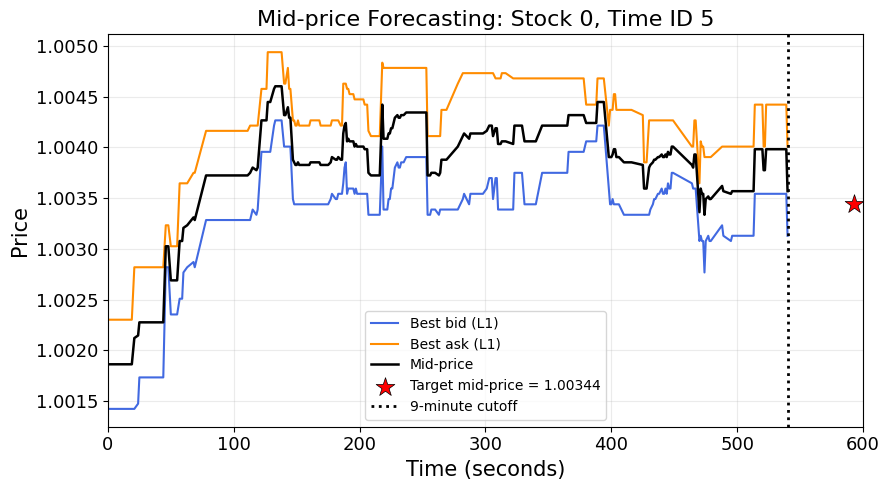

In [61]:
st_id = 0
tid = 5

# Load data
book = load_stock("book", st_id).copy()

book = book[book["time_id"] == tid].sort_values(
    "seconds_in_bucket"
).copy()

if book.empty:
    print(f"No order-book observations for stock {st_id}, time_id {tid}")

else:
    # Calculate mid-price over the full 10-minute interval
    book["MidPrice"] = (
        book["ask_price1"] + book["bid_price1"]
    ) / 2

    # Extract the actual final target
    final_price = book["MidPrice"].iloc[-1]
    final_time = book["seconds_in_bucket"].iloc[-1]

    # Only plot observed prices from the first 9 minutes
    book_9min = book[book["seconds_in_bucket"] <= 540].copy()

    fig, ax = plt.subplots(figsize=(9, 5))

    t = book_9min["seconds_in_bucket"]

    # Best bid
    ax.plot(
        t, book_9min["bid_price1"],
        color="royalblue", linewidth=1.5,
        label="Best bid (L1)"
    )

    # Best ask
    ax.plot(
        t, book_9min["ask_price1"],
        color="darkorange", linewidth=1.5,
        label="Best ask (L1)"
    )

    # Mid-price
    ax.plot(
        t, book_9min["MidPrice"],
        color="black", linewidth=1.8,
        label="Mid-price"
    )

    # Actual final mid-price (target)
    ax.scatter(
        final_time, final_price,
        color="red", marker="*", s=200,
        edgecolors="black", linewidths=0.5,
        label=f"Target mid-price = {final_price:.5f}",
        zorder=5
    )

    # 9-minute cutoff
    ax.axvline(
        540, color="black", linestyle=":",
        linewidth=2, label="9-minute cutoff"
    )

    # Axis formatting
    ax.set_xlim(0, 600)
    ax.set_xlabel("Time (seconds)", fontsize=15)
    ax.set_ylabel("Price", fontsize=15)
    ax.tick_params(axis="both", labelsize=13)

    ax.set_title(
        f"Mid-price Forecasting: Stock {st_id}, Time ID {tid}",
        fontsize=16
    )

    ax.grid(alpha=0.25)
    ax.legend(fontsize=10, loc="best")

    plt.tight_layout()
    plt.show()

# Random Mid-Price Trajectories

Plots mid-price trajectories for 500 randomly selected `time_id` windows per stock.

- **Stocks:** 0 and 1
- **Black lines:** Mid-price trajectories over the first 9 minutes (0–540 seconds)
- **Red stars:** Final observed mid-prices before 600 seconds
- **Grey shading:** Final 60-second prediction period
- **Dashed line:** 540-second prediction cutoff

A fixed random seed (`42`) ensures reproducible sampling.

The visualization supports exploratory analysis of short-horizon mid-price forecasting. Use only data up to 540 seconds as model inputs to avoid data leakage.

**Requirements:** NumPy, Pandas, Matplotlib, and the `load_stock()` data-loading function.

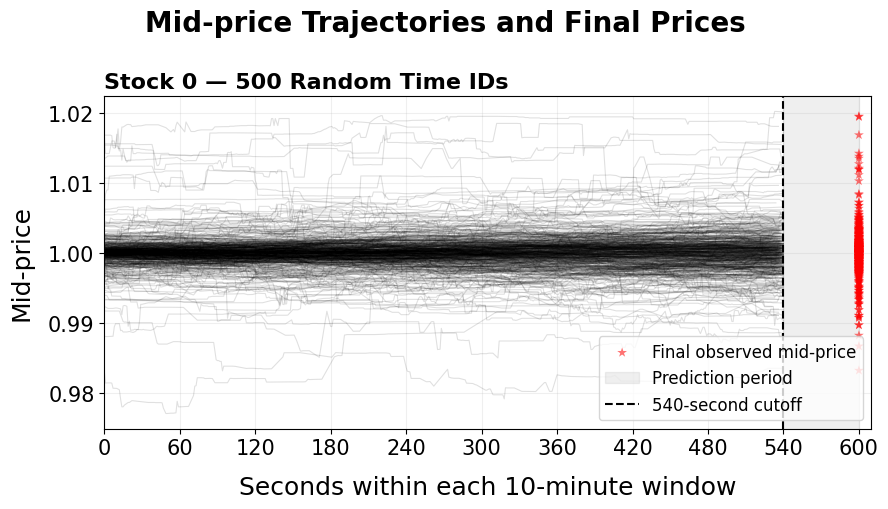

In [62]:
# Choose stocks
stock_ids = [0]

# Number of time_ids to sample per stock
n_samples = 500

rng = np.random.default_rng(seed=42)

# Narrower figure
fig, axes = plt.subplots(
    len(stock_ids), 1,
    figsize=(9, 5),
    sharex=True
)

axes = np.atleast_1d(axes)

for ax, st_id in zip(axes, stock_ids):

    # Load order-book data
    book = load_stock("book", st_id).copy()
    book = book.sort_values(["time_id", "seconds_in_bucket"])

    # Calculate mid-price
    book["MidPrice"] = (book["ask_price1"] + book["bid_price1"]) / 2

    # Randomly select time_ids
    available_time_ids = book["time_id"].unique()

    sampled_time_ids = rng.choice(
        available_time_ids,
        size=min(n_samples, len(available_time_ids)),
        replace=False
    )

    sampled_book = book[book["time_id"].isin(sampled_time_ids)]

    # Store final prices
    final_prices = []

    for tid, d in sampled_book.groupby("time_id"):

        d = d.sort_values("seconds_in_bucket")

        # First 9 minutes
        first_9 = d[d["seconds_in_bucket"] <= 540]

        # Final observed mid-price before 600 seconds
        final_price = d.loc[
            d["seconds_in_bucket"] < 600,
            "MidPrice"
        ]

        if first_9.empty or final_price.empty:
            continue

        # Mid-price trajectory: black lines
        ax.plot(
            first_9["seconds_in_bucket"],
            first_9["MidPrice"],
            color="black",
            alpha=0.12,
            linewidth=0.8
        )

        final_prices.append(final_price.iloc[-1])

    # Final mid-prices: red stars
    ax.scatter(
        [600] * len(final_prices),
        final_prices,
        color="red",
        marker="*",
        s=55,
        alpha=0.55,
        edgecolors="none",
        label="Final observed mid-price",
        zorder=5
    )

    # Shade final 60-second prediction period
    ax.axvspan(
        540, 600,
        color="grey",
        alpha=0.12,
        label="Prediction period"
    )

    # Prediction cutoff
    ax.axvline(
        540,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="540-second cutoff"
    )

    ax.set_title(
        f"Stock {st_id} — {len(sampled_time_ids)} Random Time IDs",
        fontsize=16,
        fontweight="bold",
        loc="left"
    )

    ax.set_ylabel("Mid-price", fontsize=18, labelpad=10)

    ax.tick_params(axis="both", labelsize=15)

    ax.grid(alpha=0.2)

    ax.legend(loc="best", fontsize=12)

    ax.set_xlim(0, 610)
    ax.set_xticks(np.arange(0, 601, 60))

axes[-1].set_xlabel(
    "Seconds within each 10-minute window",
    fontsize=18,
    labelpad=12
)

fig.suptitle(
    "Mid-price Trajectories and Final Prices",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

### Trade Feature Engineering

The function `engineer_trade_features()` processes trade records independently for each stock. Only trades observed at or before 540 seconds are considered, ensuring that the features use information available before the prediction period.

For each `time_id`, trade features are calculated over the recent 30-, 60-, and 120-second windows. These include:

- **Trade count:** The number of recorded trades.
- **Total traded size:** The sum of trade sizes.
- **Mean trade size:** The average size per recorded trade.
- **Total order count:** The sum of the recorded order counts.
- **Trade-price range:** Summarize price variability.
- **Last trade price:** The price of the most recent recorded trade in the window.
- **Volume-weighted average price (VWAP):** The average trade price weighted by traded size.
- **Trade-price change:** The relative change between the first and last recorded trade prices in the window.

If no trades are recorded within a window, the price-based statistics are assigned missing values, while counts and size sums are zero. This distinguishes an observed absence of trading activity from an unavailable feature value.

In [63]:
def engineer_trade_features(st_id, cutoff=300, windows=(60, 120, 180)):

    trades = load_stock("trade", st_id)
    df = trades.copy()

    df = df[df["seconds_in_bucket"] <= cutoff].copy()
    df = df.sort_values(["time_id", "seconds_in_bucket"])

    results = []

    for time_id, g in df.groupby("time_id", sort=False):
        row = {"stock_id": st_id,"time_id": time_id}

        for window in windows:
            recent = g[g["seconds_in_bucket"] > cutoff - window]

            prefix = f"trade_{window}s_"

            row[prefix + "count"] = len(recent)
            row[prefix + "size_sum"] = recent["size"].sum()
            row[prefix + "size_mean"] = recent["size"].mean()
            row[prefix + "order_count_sum"] = recent["order_count"].sum()

            if len(recent) > 0:
                prices = recent["price"]
                size_sum = recent["size"].sum()


                row[prefix + "price_range"] = prices.max() - prices.min()
                row[prefix + "last_price"] = prices.iloc[-1]

                row[prefix + "vwap"] = ((recent["price"] * recent["size"]).sum() / size_sum
                    if size_sum != 0 else np.nan)

                row[prefix + "price_change"] = (prices.iloc[-1] / prices.iloc[0] - 1
                     if prices.iloc[0] != 0 else np.nan )
            else:
                for feature in ["price_range", "last_price", "vwap", "price_change"]:
                    row[prefix + feature] = np.nan

        results.append(row)

    return pd.DataFrame(results)


### Order-Book Feature Engineering

The function `engineer_orderbook_features()` processes the order-book data separately for each stock. The data are sorted by `time_id` and `seconds_in_bucket` to preserve the temporal order of observations.

First, we calculate several snapshot-level features:

- **Mid-price:** The average of the best bid and best ask prices.
- **Bid-ask spread:** The relative difference between the best ask and best bid prices.
- **Relative spread:** The bid-ask price difference normalized by the mid-price.
- **Microprice tilt:** The difference between the size-weighted microprice and the mid-price, expressed relative to the mid-price.
- **Order-book imbalance:** The difference between the best-level bid and ask sizes, normalized by their total size.
- **Depth features:** The total bid and ask quantities across the first two price levels, along with total depth and two-level imbalance.

These features characterize price conditions, available liquidity, and the relative strength of buying and selling interest.

The function then calculates the target variable using the full order-book time series. The target is the relative change between the last available mid-price at or before 540 seconds and the last available mid-price strictly before 600 seconds. This target is stored separately from the predictive features.

To avoid using future information, the order-book observations are subsequently restricted to `seconds_in_bucket <= 540`. For each `time_id`, the features are summarized over the final 30, 60, and 120 seconds of the available input period.

For each time window, we calculate:

- **Mean values:** Represent the average market conditions during the window.
- **Standard deviations:** Capture variability in spread, imbalance, and liquidity.
- **Mid-price momentum:** Measures the logarithmic change between the first and last observed mid-prices in the window.
- **Realized variance:** Sums squared log returns within the window to characterize recent price variability.

Using multiple time windows allows the model to capture both very recent market conditions and somewhat longer-term patterns.


In [64]:


def engineer_orderbook_features(
    st_id,
    diagnostics=False,
    windows=((0, 180), (180, 240), (240, 300)),
    include_transition_features=True
):

    # Load and sort order-book data
    df = load_stock("book", st_id).copy()
    df = df.sort_values(
        ["time_id", "seconds_in_bucket"]
    ).copy()

    # Basic price features
    df["MidPrice"] = (
        df["ask_price1"] + df["bid_price1"]
    ) / 2

    df["RelativeSpread"] = (
        df["ask_price1"] - df["bid_price1"]
    ) / df["MidPrice"]

    total_top_size = df["bid_size1"] + df["ask_size1"]

    # One-level imbalance
    df["imbalance"] = (
        df["bid_size1"] - df["ask_size1"]
    ) / total_top_size.replace(0, np.nan)

    # Microprice and microprice tilt
    df["WtAvgPrice"] = (
        df["bid_price1"] * df["ask_size1"]
        + df["ask_price1"] * df["bid_size1"]
    ) / total_top_size.replace(0, np.nan)

    df["microprice_tilt"] = (
        df["WtAvgPrice"] - df["MidPrice"]
    ) / df["MidPrice"]

    if diagnostics:
        print(f"Stock ID: {st_id}")
        print("Book shape:", df.shape)
        print("Number of time IDs:", df["time_id"].nunique())
        print("Missing values:\n", df.isnull().sum())

    # Only use information available up to second 540
    df = df[df["seconds_in_bucket"] <= 300].copy()

    feature_cols = [
        "RelativeSpread",
        "imbalance",
        "microprice_tilt"
    ]

    keys = ["stock_id", "time_id"]
    df["stock_id"] = st_id

    # Reference mid-price at second 540
    last_midprice_540 = (
        df.groupby(keys)["MidPrice"]
        .last()
        .rename("last_midprice_300")
    )

    all_window_features = []

    # Calculate features for each non-overlapping interval
    for start, end in windows:

        window_name = f"{start}_{end}"

        recent = df[
            (df["seconds_in_bucket"] >= start) &
            (
                (df["seconds_in_bucket"] < end)
                if end < 300
                else (df["seconds_in_bucket"] <= end)
            )
        ].copy()

        grouped = recent.groupby(keys, sort=False)

        # Mean
        means = grouped[feature_cols].mean()
        means.columns = [
            f"{col}_mean_{window_name}"
            for col in means.columns
        ]

        # Standard deviation
        stds = grouped[feature_cols].std()
        stds.columns = [
            f"{col}_std_{window_name}"
            for col in stds.columns
        ]

        # Mid-price momentum
        prices = grouped["MidPrice"].agg(["first", "last"])

        momentum = np.log(
            prices["last"] / prices["first"]
        ).rename(f"momentum_{window_name}")

        # Realized variance within this interval
        recent["window_log_return"] = (
            np.log(recent["MidPrice"].where(recent["MidPrice"] > 0))
            .groupby([recent["stock_id"], recent["time_id"]])
            .diff()
        )

        realized_var = (
            recent.groupby(keys)["window_log_return"]
            .apply(lambda x: (x.dropna() ** 2).sum())
            .rename(f"realized_var_{window_name}")
        )

        window_features = pd.concat(
            [means, stds, momentum, realized_var],
            axis=1
        ).reset_index()

        all_window_features.append(window_features)

    # Merge all interval features
    result = all_window_features[0]

    for window_features in all_window_features[1:]:
        result = result.merge(
            window_features,
            on=keys,
            how="outer",
            validate="one_to_one"
        )

    # Add reference mid-price
    result = result.merge(
        last_midprice_540.reset_index(),
        on=keys,
        how="left",
        validate="one_to_one"
    )

    # --------------------------------------------------
    # Optional: Transition features between intervals
    # --------------------------------------------------

    if include_transition_features:

        if len(windows) != 3:
            raise ValueError(
                "Transition features currently require exactly 3 windows."
            )

        intervals = [f"{start}_{end}" for start, end in windows]

        # Differences in means and standard deviations
        for feature in feature_cols:

            for stat in ["mean", "std"]:

                col1 = f"{feature}_{stat}_{intervals[0]}"
                col2 = f"{feature}_{stat}_{intervals[1]}"
                col3 = f"{feature}_{stat}_{intervals[2]}"

                result[f"{feature}_{stat}_diff_2_1"] = (
                    result[col2] - result[col1]
                )

                result[f"{feature}_{stat}_diff_3_2"] = (
                    result[col3] - result[col2]
                )

        # Differences in momentum
        result["momentum_diff_2_1"] = (
            result[f"momentum_{intervals[1]}"]
            - result[f"momentum_{intervals[0]}"]
        )

        result["momentum_diff_3_2"] = (
            result[f"momentum_{intervals[2]}"]
            - result[f"momentum_{intervals[1]}"]
        )

        # Differences in realized variance
        result["realized_var_diff_2_1"] = (
            result[f"realized_var_{intervals[1]}"]
            - result[f"realized_var_{intervals[0]}"]
        )

        result["realized_var_diff_3_2"] = (
            result[f"realized_var_{intervals[2]}"]
            - result[f"realized_var_{intervals[1]}"]
        )

        # Relative changes in mean relative spread
        eps = 1e-8

        spread_1 = result[
            f"RelativeSpread_mean_{intervals[0]}"
        ]

        spread_2 = result[
            f"RelativeSpread_mean_{intervals[1]}"
        ]

        spread_3 = result[
            f"RelativeSpread_mean_{intervals[2]}"
        ]

        result["RelativeSpread_relchange_2_1"] = (
            (spread_2 - spread_1)
            / spread_1.abs().clip(lower=eps)
        )

        result["RelativeSpread_relchange_3_2"] = (
            (spread_3 - spread_2)
            / spread_2.abs().clip(lower=eps)
        )

    return result


### Combining Features Across Stocks

The feature-engineering functions are applied separately to every stock in the training data. The resulting tables are then concatenated to create three datasets:

- `X`: Order-book features for all stocks and time intervals.
- `T`: Trade features for all stocks and time intervals.
- `Y`: Target values, including the starting mid-price, final mid-price, and relative mid-price change.

The order-book and trade feature tables are merged using `stock_id` and `time_id` as keys. This produces `X_combined`, which contains both types of predictive features for each stock and time interval.

The target table remains separate so that the target variable is not inadvertently included among the model inputs. Before model training, the merged data will be checked for duplicate keys, missing values, and consistency between features and targets.

In [65]:
stock_ids=np.sort(book_st_id)

all_features = []
all_trade_features = []

for st_id in stock_ids:
    print(f"Processing stock {st_id}")

  #  features = engineer_orderbook_features(st_id=st_id, diagnostics=False)
    features = engineer_orderbook_features(
    st_id=st_id,
    include_transition_features=True
)
   # trade_features = engineer_trade_features(st_id=st_id)

    all_features.append(features)
   # all_trade_features.append(trade_features)






Processing stock 0
Processing stock 1
Processing stock 2
Processing stock 3
Processing stock 4
Processing stock 5
Processing stock 6
Processing stock 7
Processing stock 8
Processing stock 9
Processing stock 10
Processing stock 11
Processing stock 13
Processing stock 14
Processing stock 15
Processing stock 16
Processing stock 17
Processing stock 18
Processing stock 19
Processing stock 20
Processing stock 21
Processing stock 22
Processing stock 23
Processing stock 26
Processing stock 27
Processing stock 28
Processing stock 29
Processing stock 30
Processing stock 31
Processing stock 32
Processing stock 33
Processing stock 34
Processing stock 35
Processing stock 36
Processing stock 37
Processing stock 38
Processing stock 39
Processing stock 40
Processing stock 41
Processing stock 42
Processing stock 43
Processing stock 44
Processing stock 46
Processing stock 47
Processing stock 48
Processing stock 50
Processing stock 51
Processing stock 52
Processing stock 53
Processing stock 55
Processing

In [66]:
# Combine every stock
X_orderbook = pd.concat(all_features, ignore_index=True)
#X_trade = pd.concat(all_trade_features, ignore_index=True)

print("Order-book features:", X_orderbook.shape)
#print("Trade features:", X_trade.shape)

## discard the time ids when there is no trade

X=X_orderbook
#X = X_orderbook.merge(X_trade, on=["stock_id", "time_id"],
#    how="inner", validate="one_to_one")


print("Feature matrix shape:", X.shape)
print("Number of stocks:", X["stock_id"].nunique())
print("Number of stock/time_id rows:", X[["stock_id", "time_id"]].drop_duplicates().shape[0])

display(X.head())

print("Target matrix shape:", Y.shape)
print("Number of stocks:", Y["stock_id"].nunique())
print("Number of stock/time_id rows:", Y[["stock_id", "time_id"]].drop_duplicates().shape[0])

display(Y.head())

Order-book features: (428932, 45)
Feature matrix shape: (428932, 45)
Number of stocks: 112
Number of stock/time_id rows: 428932


,stock_id,time_id,RelativeSpread_mean_0_180,imbalance_mean_0_180,microprice_tilt_mean_0_180,RelativeSpread_std_0_180,imbalance_std_0_180,microprice_tilt_std_0_180,momentum_0_180,realized_var_0_180,...,microprice_tilt_mean_diff_2_1,microprice_tilt_mean_diff_3_2,microprice_tilt_std_diff_2_1,microprice_tilt_std_diff_3_2,momentum_diff_2_1,momentum_diff_3_2,realized_var_diff_2_1,realized_var_diff_3_2,RelativeSpread_relchange_2_1,RelativeSpread_relchange_3_2
0,0,5,0.000821,-0.084063,-0.000029,0.000157,0.774035,0.000329,0.002037,1.662529e-06,...,0.000120,-0.000219,-0.000130,0.000184,-0.001573,-0.000670,-8.866843e-07,-3.420461e-07,0.139895,0.043769
1,0,11,0.000577,-0.294972,-0.000082,0.000177,0.586856,0.000172,0.000226,1.882386e-07,...,0.000257,-0.000186,-0.000125,0.000090,-0.000351,0.000477,-1.611432e-07,5.472765e-08,-0.314408,-0.278667
2,0,16,0.000782,0.308259,0.000114,0.000133,0.415080,0.000160,0.000000,3.252549e-07,...,-0.000246,0.000046,-0.000005,0.000031,-0.000718,0.001389,-1.913264e-09,-4.134176e-08,-0.272167,0.335977
3,0,31,0.000826,-0.006281,-0.000066,0.000283,0.676607,0.000284,-0.001505,6.079687e-07,...,-0.000014,0.000347,-0.000018,-0.000145,0.001435,-0.000116,-6.052870e-07,2.632659e-08,0.467898,-0.362023
4,0,62,0.000386,0.262075,0.000041,0.000099,0.696540,0.000145,-0.000140,3.315856e-07,...,0.000017,0.000052,-0.000027,-0.000026,0.000210,-0.000373,-2.973658e-07,3.916911e-08,-0.243922,0.383811


Target matrix shape: (428932, 5)
Number of stocks: 112
Number of stock/time_id rows: 428932


,stock_id,time_id,midprice_300,midprice_last,midprice_relchange
0,0,5,1.004137,1.003439,-0.000695
1,0,11,1.000276,1.000527,0.000251
2,0,16,0.999952,0.997798,-0.002154
3,0,31,0.998381,0.997941,-0.000440
4,0,62,0.999534,0.999930,0.000396


## Data Quality Checks Before Model Training

Before training the predictive models, we perform several checks to assess the quality and consistency of the engineered features and target variables.

### 1. Check for Duplicate Observations

Each row should represent a unique combination of `stock_id` and `time_id`. We therefore check whether either the feature table (`X`) or the target table (`Y`) contains duplicate keys. Duplicate observations could cause incorrect matches when features and targets are combined.

### 2. Check Missing Values in the Feature Matrix

We calculate the total number of missing values in `X` and identify which features contain them. Examining missing values feature by feature helps us understand whether they arise from insufficient observations within a time window, unavailable price statistics, or other data-quality issues.

Missing values should be investigated before model training. Depending on the feature and model, they may require imputation, an appropriate missing-value treatment, or removal of observations or features.

### 3. Check Missing Values in the Target Variables

We inspect missing values in the starting mid-price (`midprice_540`), final mid-price (`midprice_last`), and relative mid-price change (`target_relchange`).

Observations with missing or invalid target values cannot be used as supervised training examples. These rows should be excluded from model training, while ensuring that the corresponding feature rows remain correctly aligned with their targets.

These checks help identify potential data-quality problems before proceeding to model preparation and training.

In [68]:
# checks before training

# check if there are duplicate rows

print("Duplicate feature rows:", X.duplicated(["stock_id", "time_id"]).sum())
print("Duplicate target rows:", Y.duplicated(["stock_id", "time_id"]).sum())

print("Total NaN values in X:", X.isna().sum().sum())
print("\n NaN values per feature:")
print(X.isna().sum()[X.isna().sum() > 0].sort_values(ascending=False))

# check for NAN in Y
print("\n NaN values in Y:")
print(Y[["midprice_300", "midprice_last", "midprice_relchange"]].isna().sum())


Duplicate feature rows: 0
Duplicate target rows: 0
Total NaN values in X: 1656

 NaN values per feature:
microprice_tilt_std_diff_3_2     150
imbalance_std_diff_3_2           150
RelativeSpread_std_diff_3_2      150
microprice_tilt_std_240_300       78
RelativeSpread_std_240_300        78
imbalance_std_240_300             78
imbalance_std_diff_2_1            77
imbalance_std_180_240             77
microprice_tilt_std_180_240       77
RelativeSpread_std_180_240        77
RelativeSpread_std_diff_2_1       77
microprice_tilt_std_diff_2_1      77
momentum_diff_3_2                 36
realized_var_diff_3_2             36
imbalance_mean_diff_3_2           36
microprice_tilt_mean_diff_3_2     36
RelativeSpread_mean_diff_3_2      36
RelativeSpread_relchange_3_2      36
imbalance_mean_180_240            19
RelativeSpread_mean_180_240       19
microprice_tilt_mean_180_240      19
imbalance_mean_diff_2_1           19
microprice_tilt_mean_diff_2_1     19
realized_var_180_240              19
momentu

### Checking Observation Counts and Missing Trade Features

To understand the NaN values in the engineered features, we count the number of order-book and trade observations available for each stock and time window over the final 60, 120, and 180 seconds before the prediction cutoff at 540 seconds.

For each `(stock_id, time_id)` pair, we classify the number of observations as zero, one, or more than one. This helps identify whether missing feature values arise from insufficient observations.

For trade features, windows with no trades have undefined price statistics, such as the last trade price, VWAP, price range, and price change. With only one trade, the sample standard deviation is also undefined, although the price range and price change should be zero. For order-book features, a window with only one observation cannot provide a sample standard deviation.

Comparing these observation counts with the NaN counts in the engineered features helps verify the source of missing values and determine how they should be handled before model training.

In [14]:
# check the reason of NaN values in X: zero trade windows, zero orderbook windows, one orderbook windows

for window in [60, 120, 180]:

    count_col = f"trade_{window}s_count"

    zero_trades = (X[count_col] == 0).sum()
    one_trade = (X[count_col] == 1).sum()

    print(f"\n--- {window}-second window ---")
    print("Zero-trade windows:", zero_trades)
  #  print("One-trade windows:", one_trade)

    for feature in [
        "price_range",
        "size_mean",
        "last_price",
        "vwap",
        "price_change",
        "price_std"
    ]:
        col = f"trade_{window}s_{feature}"

        if col in X.columns:
            nan_count = X[col].isna().sum()
            print(f"{feature} NaNs: {nan_count}")

windows = [60, 120, 180]
all_counts = []

# Count observations in each window for every stock/time_id
for st_id in sorted(X["stock_id"].unique()):

    df_stock = load_stock("book", st_id).copy()

    stock_time_ids = X.loc[X["stock_id"] == st_id, "time_id"].unique()

    for window in windows:

        start_time = 540 - window

        df_recent = df_stock[
            (df_stock["seconds_in_bucket"] >= start_time) &
            (df_stock["seconds_in_bucket"] <= 540)]

        counts = df_recent.groupby("time_id").size()
        counts = counts.reindex(stock_time_ids, fill_value=0)

        temp = counts.rename("n_observations").reset_index()
        temp = temp.rename(columns={"index": "time_id"})
        temp["stock_id"] = st_id
        temp["window"] = window

        all_counts.append(temp)

counts_all_windows = pd.concat(all_counts, ignore_index=True)


# Summarize observation counts
for window in windows:

    counts = counts_all_windows.loc[
        counts_all_windows["window"] == window,
        "n_observations"]

    print(f"\n--- {window}-second window ---")
    print("Zero-orderbook windows:", (counts == 0).sum())
    print("One-orderbook windows:", (counts == 1).sum())


KeyError: 'trade_60s_count'

In [69]:
# treating the NaN values in X

X1 = X.copy()

X1["trade_60s_last_price"] = (X1["trade_60s_last_price"].fillna(X1["last_midprice_540"]))
X1["trade_60s_vwap"] = (X1["trade_60s_vwap"].fillna(X1["last_midprice_540"]))
X1["trade_60s_price_change"] = X1["trade_60s_price_change"].fillna(0)
X1["trade_60s_price_range"] = X1["trade_60s_price_range"].fillna(0)
X1["trade_60s_size_mean"] = X1["trade_60s_size_mean"].fillna(0)

X1["trade_120s_last_price"] = (X1["trade_120s_last_price"].fillna(X1["last_midprice_540"]))
X1["trade_120s_vwap"] = (X1["trade_120s_vwap"].fillna(X1["last_midprice_540"]))
X1["trade_120s_price_change"] = X1["trade_120s_price_change"].fillna(0)
X1["trade_120s_price_range"] = X1["trade_120s_price_range"].fillna(0)
X1["trade_120s_size_mean"] = X1["trade_120s_size_mean"].fillna(0)

X1["trade_180s_last_price"] = (X1["trade_180s_last_price"].fillna(X1["last_midprice_540"]))
X1["trade_180s_vwap"] = (X1["trade_180s_vwap"].fillna(X1["last_midprice_540"]))
X1["trade_180s_price_change"] = X1["trade_180s_price_change"].fillna(0)
X1["trade_180s_price_range"] = X1["trade_180s_price_range"].fillna(0)
X1["trade_180s_size_mean"] = X1["trade_180s_size_mean"].fillna(0)

# Mean features: median imputation

mean_cols = [
    "RelativeSpread_mean_60s",
    "BidAskSpread_mean_60s",
    "imbalance_2level_mean_60s",
    "total_depth_mean_60s",
    "ask_depth_mean_60s",
    "bid_depth_mean_60s",
    "microprice_tilt_mean_60s",
    "imbalance_mean_60s"
]


for col in mean_cols:
    X1[col] = X1[col].fillna(X1[col].median())

mean_cols = [c for c in X1.columns if "_mean_" in c]


std_cols = [
    "bid_depth_std_60s",
    "RelativeSpread_std_60s",
    "BidAskSpread_std_60s",
    "imbalance_2level_std_60s",
    "total_depth_std_60s",
    "ask_depth_std_60s",
    "microprice_tilt_std_60s",
    "imbalance_std_60s"
]

X1[std_cols] = X1[std_cols].fillna(0)

X1["momentum_60s"] = X1["momentum_60s"].fillna(0)
X1["realized_var_60s"] = X1["realized_var_60s"].fillna(0)


std_cols_120 = [
    "total_depth_std_120s",
    "ask_depth_std_120s",
    "bid_depth_std_120s",
    "imbalance_std_120s",
    "microprice_tilt_std_120s",
    "RelativeSpread_std_120s",
    "BidAskSpread_std_120s",
    "imbalance_2level_std_120s"
]

X1[std_cols_120] = X1[std_cols_120].fillna(0)

print("Total NaN values in X:", X1.isna().sum().sum())
print("\n NaN values per feature:")
print(X1.isna().sum()[X1.isna().sum() > 0].sort_values(ascending=False))



Total NaN values in X: 0

 NaN values per feature:
Series([], dtype: int64)


In [32]:
# checking the reason of NaN values in Y: no observation after 540 seconds

availability_all = []

for st_id in sorted(X["stock_id"].unique()):

    # Load order-book data
    df = load_stock("book", st_id).copy()

    # Sort by time
    df = df.sort_values(["time_id", "seconds_in_bucket"])

    # Check whether each time_id has observations after 540 seconds
    availability = (
        df.groupby("time_id")["seconds_in_bucket"]
          .apply(lambda x: (x > 540).any())
          .reset_index(name="has_observations_after_540")
    )

    availability["stock_id"] = st_id

    availability_all.append(availability)

# Combine all stocks
availability_all = pd.concat(availability_all, ignore_index=True)

# Count missing final-minute observations
total_groups = len(availability_all)

no_final_observations = (
    ~availability_all["has_observations_after_540"]
).sum()

# Results
print("Total stock-time_id groups:", total_groups)

print("Groups with no observations after 540 seconds:",
      no_final_observations)

print("Percentage without final-minute observations:",
      round(100 * no_final_observations / total_groups, 2), "%")

# Breakdown by stock
print("\nBreakdown by stock:")

print(
    availability_all.groupby("stock_id")[
        "has_observations_after_540"
    ].agg(
        total_groups="count",
        groups_with_observations="sum"
    )
)

Total stock-time_id groups: 428932
Groups with no observations after 540 seconds: 82
Percentage without final-minute observations: 0.02 %

Breakdown by stock:
          total_groups  groups_with_observations
stock_id                                        
0                 3830                      3828
1                 3830                      3830
2                 3830                      3830
3                 3830                      3830
4                 3830                      3830
...                ...                       ...
122               3830                      3830
123               3830                      3830
124               3830                      3830
125               3830                      3830
126               3830                      3829

[112 rows x 2 columns]


In [69]:
# Remove rows with invalid targets

X1 = X.copy()
# rows which does not contain trade activity has been dropped from X
X_updated = X1.copy()

# drop rows where there is NAN
Y_updated = Y.dropna(subset=["midprice_300", "midprice_last", "midprice_relchange"]).copy()

print("Total NaN values in X:", X_updated.isna().sum().sum())
print("Total NaN values in Y:", Y_updated.isna().sum().sum())


# Keep only feature rows whose targets are valid
keys = ["stock_id", "time_id"]

X_updated = X_updated.merge(Y_updated[keys], on=keys, how="inner", validate="one_to_one")
Y_updated = X_updated[keys].merge(Y_updated, on=keys, how="inner", validate="one_to_one")


print("Rows in Y_updated:", len(Y_updated))
print("Rows in X_updated:", len(X_updated))


# checks if all stock id and time id has corresponding rows in X and Y
X_keys = X_updated[["stock_id", "time_id"]].drop_duplicates()
Y_keys = Y_updated[["stock_id", "time_id"]].drop_duplicates()

comparison = X_keys.merge(Y_keys, on=["stock_id", "time_id"], how="outer", indicator=True)

print(comparison["_merge"].value_counts())


Total NaN values in X: 1656
Total NaN values in Y: 0
Rows in Y_updated: 428932
Rows in X_updated: 428932
_merge
both          428932
left_only          0
right_only         0
Name: count, dtype: int64


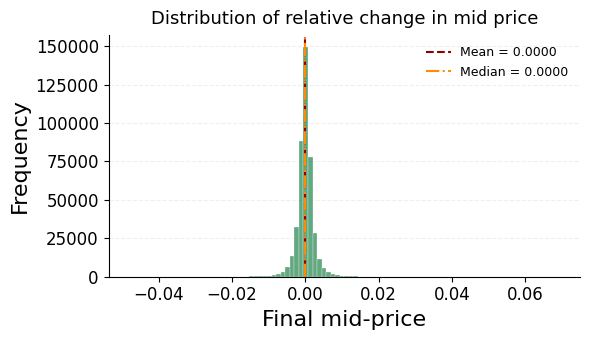

count    428932.000000
mean          0.000017
std           0.002472
min          -0.051244
25%          -0.000953
50%           0.000000
75%           0.000991
max           0.072469
Name: midprice_relchange, dtype: float64


In [70]:
price = Y_updated["midprice_relchange"]

mean_price = price.mean()
median_price = price.median()
fig, ax = plt.subplots(figsize=(6, 3.5))

sns.histplot(
    price,
    bins=100,
    color="seagreen",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.2,
    ax=ax
)

ax.axvline(
    mean_price,
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {mean_price:.4f}"
)

ax.axvline(
    median_price,
    color="darkorange",
    linestyle="-.",
    linewidth=1.5,
    label=f"Median = {median_price:.4f}"
)

ax.set_title("Distribution of relative change in mid price", fontsize=13, pad=8)
ax.set_xlabel("Final mid-price", fontsize=16)
ax.set_ylabel("Frequency", fontsize=16)

ax.tick_params(axis="both", labelsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.legend(fontsize=9, frameon=False)

sns.despine()
x_min = price.min()
x_max = price.max()
margin = 0.02 * (x_max - x_min)

ax.set_xlim(x_min - margin, x_max + margin)
plt.tight_layout()
plt.show()



print(price.describe().round(6))

In [58]:
print("Target statistics:")
print(Y_updated["midprice_relchange"].describe(percentiles=[
    0.001, 0.01, 0.05, 0.10,
    0.25, 0.50, 0.75, 0.90,
    0.95, 0.99, 0.999
]))

print("\nFraction of observations close to zero:")

for threshold in [0.0001, 0.0002, 0.0005, 0.001]:
    fraction = (y_train.abs() < threshold).mean()
    print(f"|y| < {threshold}: {fraction:.2%}")

Target statistics:
count    428932.000000
mean         -0.000005
std           0.003688
min          -0.084142
0.1%         -0.023745
1%           -0.010519
5%           -0.005097
10%          -0.003362
25%          -0.001432
50%           0.000000
75%           0.001427
90%           0.003312
95%           0.005022
99%           0.010626
99.9%         0.023749
max           0.112484
Name: midprice_relchange, dtype: float64

Fraction of observations close to zero:
|y| < 0.0001: 16.91%
|y| < 0.0002: 29.02%
|y| < 0.0005: 57.19%
|y| < 0.001: 80.24%


In [26]:
drop_features = [
    "BidAskSpread_mean_60s",
    "BidAskSpread_mean_120s",
    "BidAskSpread_mean_180s",

    "BidAskSpread_std_60s",
    "BidAskSpread_std_120s",
    "BidAskSpread_std_180s",

    "trade_120s_last_price",
    "trade_180s_last_price",

    "total_depth_mean_180s",
    "total_depth_mean_120s",
     "total_depth_mean_60s",

    "total_depth_std_180s",
    "total_depth_std_120s",

    "bid_depth_mean_180s",
    "bid_depth_mean_120s",

    "bid_depth_std_120s",
    "bid_depth_std_60s",

    "ask_depth_mean_180s",
    "ask_depth_mean_120s",

    "ask_depth_std_180s",
    "bid_depth_std_180s",

    "ask_depth_std_120s",

    "trade_120s_vwap",
    "trade_180s_vwap",

    "RelativeSpread_mean_180s",
    "RelativeSpread_mean_120s",
    "RelativeSpread_mean_60s",


    "RelativeSpread_std_180s",
    "RelativeSpread_std_120s",

    "microprice_tilt_std_180s",
    "microprice_tilt_std_120s",
    "microprice_tilt_std_60s",

    "microprice_tilt_mean_180s",
    "microprice_tilt_mean_120s",

    "trade_180s_count",
    "trade_120s_count",

    "trade_180s_order_count_sum",
    "trade_120s_order_count_sum",

    "trade_180s_size_sum",
    "trade_120s_size_sum",

    "trade_180s_size_mean",

    "trade_60s_last_price",

    "trade_180s_price_range",
    "trade_120s_price_range",

    "trade_180s_price_change",
    "trade_120s_price_change",

     "trade_60s_price_change",

    "realized_var_180s",

    "imbalance_2level_mean_120s",
    "imbalance_2level_std_120s",
    "imbalance_2level_mean_180s",
    "imbalance_2level_std_180s",

    "imbalance_mean_180s",
    "imbalance_mean_120s",

    "imbalance_std_120s",
     "realized_var_120s",
     "imbalance_std_180s",

     "momentum_180s",
     "momentum_120s"

]


X_updated = X_updated.drop(columns=drop_features)

print("Shape:", X_updated.shape)

Shape: (428817, 22)


                            Pearson  Spearman  abs_Pearson
microprice_tilt_mean_60s   0.014235  0.012909     0.014235
trade_60s_price_range      0.011963  0.008974     0.011963
realized_var_60s           0.011369  0.005752     0.011369
imbalance_mean_60s         0.010236  0.012662     0.010236
imbalance_2level_mean_60s  0.009660  0.010721     0.009660
RelativeSpread_std_60s     0.008524  0.003450     0.008524
trade_60s_count            0.006727  0.009034     0.006727
trade_60s_order_count_sum  0.005501  0.009620     0.005501
imbalance_std_60s          0.003726  0.005517     0.003726
imbalance_2level_std_60s   0.002840  0.004880     0.002840
trade_60s_size_sum         0.002286  0.007160     0.002286
ask_depth_mean_60s        -0.002286 -0.003693     0.002286
total_depth_std_60s        0.001667  0.002647     0.001667
trade_120s_size_mean      -0.001623  0.002249     0.001623
bid_depth_mean_60s        -0.000423  0.003266     0.000423


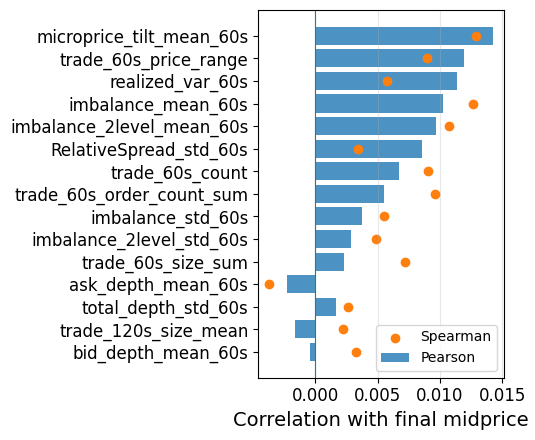

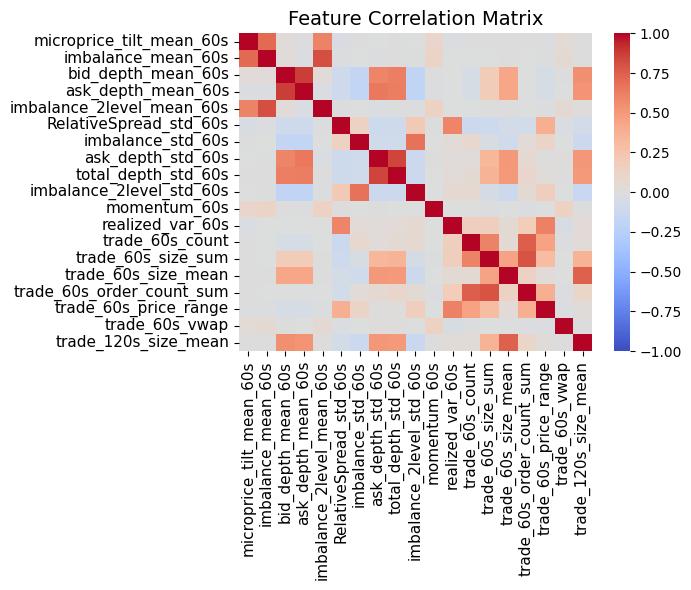

In [51]:
X_features = X_updated.drop(columns=["stock_id", "time_id", "last_midprice_540"])

# Select the target
y = Y_updated["midprice_relchange"]

pearson = X_features.corrwith(y, method="pearson")
spearman = X_features.corrwith(y, method="spearman")


corr_summary = pd.DataFrame({
    "Pearson": pearson,
    "Spearman": spearman
})

corr_summary["abs_Pearson"] = corr_summary["Pearson"].abs()

corr_summary = corr_summary.sort_values(
    "abs_Pearson", ascending=False
)

print(corr_summary.head(15))

top15 = corr_summary.head(15).sort_values("abs_Pearson")
fig, ax = plt.subplots(figsize=(5.5, 4.5))

y_pos = range(len(top15))

ax.barh(
    y_pos,
    top15["Pearson"],
    label="Pearson",
    alpha=0.8
)

ax.scatter(
    top15["Spearman"],
    y_pos,
    label="Spearman",
    marker="o"
)

ax.set_yticks(y_pos)
ax.set_yticklabels(top15.index)
ax.set_xlabel("Correlation with final midprice", fontsize=14)
#ax.set_title("Correlation with final midprice", fontsize=14)
ax.axvline(0, linewidth=0.8)
ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=12)
plt.tight_layout()
plt.show()

# Feature-to-feature correlation
corr_matrix = X_features.corr(method="pearson")

plt.figure(figsize=(7, 6))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Feature Correlation Matrix", fontsize=14)
plt.xticks(fontsize=11, rotation=90)
plt.yticks(fontsize=11, rotation=0)
plt.tight_layout()
plt.show()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)



In [39]:
# Find pairs with absolute correlation above 0.90
high_corr_pairs = (
    upper.stack()
    .reset_index()
)

high_corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

high_corr_pairs["abs_corr"] = high_corr_pairs["Correlation"].abs()

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["abs_corr"] > 0.85
].sort_values("abs_corr", ascending=False)

display(high_corr_pairs.style.hide(axis="index"))


Feature_1,Feature_2,Correlation,abs_corr
bid_depth_mean_60s,ask_depth_mean_60s,0.868841,0.868841


In [40]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif_array = X_features.to_numpy()

vif = pd.DataFrame({
    "Feature": X_features.columns,
    "VIF": [
        variance_inflation_factor(X_vif_array, i)
        for i in range(X_vif_array.shape[1])
    ]
})

vif = vif.sort_values("VIF", ascending=False)

print(vif.head(25))

                      Feature       VIF
3          ask_depth_mean_60s  4.686348
15  trade_60s_order_count_sum  4.635253
2          bid_depth_mean_60s  4.569410
13         trade_60s_size_sum  4.483235
7           ask_depth_std_60s  3.976078
1          imbalance_mean_60s  3.945788
8         total_depth_std_60s  3.944693
4   imbalance_2level_mean_60s  3.041215
12            trade_60s_count  2.777483
14        trade_60s_size_mean  2.733176
18       trade_120s_size_mean  2.675018
11           realized_var_60s  2.213728
16      trade_60s_price_range  2.136695
0    microprice_tilt_mean_60s  2.076175
9    imbalance_2level_std_60s  1.952441
5      RelativeSpread_std_60s  1.909366
6           imbalance_std_60s  1.870439
10               momentum_60s  1.040356
17             trade_60s_vwap  1.024296


In [72]:
from sklearn.model_selection import train_test_split

unique_time_ids = Y_updated["time_id"].unique()

# Split time IDs: 80% train, 20% test
train_time_ids, test_time_ids = train_test_split(
    unique_time_ids,
    test_size=0.20,
    random_state=42
)

print("Number of training time IDs:", len(train_time_ids))
print("Number of testing time IDs:", len(test_time_ids))

X_train = X_updated[X_updated["time_id"].isin(train_time_ids)].copy()

X_test = X_updated[X_updated["time_id"].isin(test_time_ids)].copy()

# Filter targets
Y_train = Y_updated[Y_updated["time_id"].isin(train_time_ids)].copy()

Y_test = Y_updated[Y_updated["time_id"].isin(test_time_ids)].copy()

keys = ["stock_id", "time_id"]

train_data = X_train.merge(Y_train[keys + ["midprice_relchange"]],on=keys, how="inner", validate="one_to_one")

test_data = X_test.merge(Y_test[keys + ["midprice_relchange"]], on=keys, how="inner", validate="one_to_one")

y_train = train_data["midprice_relchange"]

y_test = test_data["midprice_relchange"]

X_train_model = train_data.drop(
    columns=keys + ["midprice_relchange", "last_midprice_300"]
)

X_test_model = test_data.drop(
    columns=keys + ["midprice_relchange", "last_midprice_300"]
)

print("\nTraining features:", X_train_model.shape)
print("Training target:", y_train.shape)
print("Testing features:", X_test_model.shape)
print("Testing target:", y_test.shape)

print("\nMissing training targets:", y_train.isna().sum())
print("Missing testing targets:", y_test.isna().sum())

print("Overlapping time IDs:", len(set(train_time_ids) & set(test_time_ids)))

print("Training target mean:", y_train.mean())
print("Training target std:", y_train.std())

print("Test target mean:", y_test.mean())
print("Test target std:", y_test.std())

print("Test target min:", y_test.min())
print("Test target max:", y_test.max())


Number of training time IDs: 3064
Number of testing time IDs: 766

Training features: (343146, 42)
Training target: (343146,)
Testing features: (85786, 42)
Testing target: (85786,)

Missing training targets: 0
Missing testing targets: 0
Overlapping time IDs: 0
Training target mean: 2.2441991e-05
Training target std: 0.0024762817192822695
Test target mean: -4.246843e-06
Test target std: 0.0024562054313719273
Test target min: -0.04597945883870125
Test target max: 0.0503566637635231


In [73]:
# 4. Evaluate each model, including persistence baseline
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_validate
import time as time
all_results = []
total_start = time.time()

for model_number, (name, model) in enumerate(models.items(), start=1):

    print(f"\n{'='*55}", flush=True)
    print(f"Model {model_number}/{len(models)}: {name}", flush=True)
    print("Starting 10-fold cross-validation...", flush=True)
    print(f"{'='*55}", flush=True)

    model_start = time.time()

    scores = cross_validate(
        estimator=model,
        X=X_train_model,
        y=y_train,
        groups=groups,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=-1,
        return_train_score=False,
        verbose=2
    )

    fold_rmse = -scores["test_rmse"]
    fold_mae = -scores["test_mae"]
    fold_r2 = scores["test_r2"]

    for fold in range(len(fold_rmse)):
        all_results.append({
            "Model": name,
            "Fold": fold + 1,
            "RMSE": fold_rmse[fold],
            "MAE": fold_mae[fold],
            "R2": fold_r2[fold]
        })

    print(f"\n{name} completed.", flush=True)
    print(f"Elapsed time: {(time.time() - model_start)/60:.2f} minutes")
    print("Fold RMSE:", np.round(fold_rmse, 6))
    print("Fold MAE: ", np.round(fold_mae, 6))
    print("Fold R²:  ", np.round(fold_r2, 4))


# --------------------------------------------------
# Persistence baseline: predict midprice_last using
# last_midprice_540
# --------------------------------------------------

print("\nEvaluating Persistence Baseline...", flush=True)

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train_model, y_train, groups),
    start=1
):

    actual = y_train.iloc[val_idx].to_numpy()

    predicted = np.zeros(len(val_idx))

    all_results.append({
        "Model": "Persistence Baseline",
        "Fold": fold,
        "RMSE": root_mean_squared_error(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "R2": r2_score(actual, predicted)
    })

# Store all results
fold_results = pd.DataFrame(all_results)


Model 1/4: Mean Baseline
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


ValueError: Found input variables with inconsistent numbers of samples: [343146, 343146, 343081]

In [41]:
print("\nPersistence Baseline Results:")

persistence_results = pd.DataFrame(
    [r for r in all_results if r["Model"] == "Persistence Baseline"]
)

print(persistence_results.round(6).to_string(index=False))

print("\nPersistence Baseline Summary:")
print(
    persistence_results[["RMSE", "MAE", "R2"]]
    .agg(["mean", "std"])
    .round(6)
)


Persistence Baseline Results:
               Model  Fold     RMSE      MAE        R2
Persistence Baseline     1 0.001023 0.000649 -0.000009
Persistence Baseline     2 0.001032 0.000640 -0.001238
Persistence Baseline     3 0.001024 0.000636 -0.000048
Persistence Baseline     4 0.001101 0.000687 -0.000249
Persistence Baseline     5 0.001068 0.000650 -0.000330
Persistence Baseline     6 0.001034 0.000634 -0.000969
Persistence Baseline     7 0.001082 0.000684 -0.000334
Persistence Baseline     8 0.001055 0.000630 -0.000658
Persistence Baseline     9 0.001139 0.000687 -0.000418
Persistence Baseline    10 0.001082 0.000670 -0.000164

Persistence Baseline Summary:
          RMSE       MAE        R2
mean  0.001064  0.000657 -0.000442
std   0.000038  0.000023  0.000400


In [74]:

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import ElasticNet
import time

# 1. Define the three models
models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),

    "Ridge Regression_alpha1": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Elastic Net": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        ElasticNet(
            alpha=0.001,
            l1_ratio=0.2,
            max_iter=10000
        )
    ),



    "XGBoost": make_pipeline(
        SimpleImputer(strategy="median"),
        XGBRegressor(
            n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    device="cuda",
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2
        )
    ),

   # "Random Forest": make_pipeline(
   #  SimpleImputer(strategy="median"),
   #  RandomForestRegressor(
   #  n_estimators=50,
   #  max_depth=12,
   #  min_samples_leaf=20,
   #  max_features=0.7,
   #  random_state=42,
   #  n_jobs=2
   #     )
   # ),
}

# 2. Group observations by time_id
groups = train_data["time_id"].to_numpy()

# 3. Set up 10-fold cross-validation
cv = GroupKFold(n_splits=10)

# 4. Evaluate each model
all_results = []
total_start = time.time()

for model_number, (name, model) in enumerate(models.items(), start=1):

    print(f"\n{'='*55}", flush=True)
    print(f"Model {model_number}/{len(models)}: {name}", flush=True)
    print(f"Starting 10-fold cross-validation...", flush=True)
    print(f"{'='*55}", flush=True)

    model_start = time.time()

    scores = cross_validate(
        estimator=model,
        X=X_train_model,
        y=y_train,
        groups=groups,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
             "r2": "r2"
        },
        n_jobs=-1,
        return_train_score=False,
        verbose=2
    )

    # Convert negative scores to positive errors
    fold_rmse = -scores["test_rmse"]
    fold_mae = -scores["test_mae"]
    fold_r2 = scores["test_r2"]

    for fold in range(len(fold_rmse)):
        all_results.append({
            "Model": name,
            "Fold": fold + 1,
            "RMSE": fold_rmse[fold],
            "MAE": fold_mae[fold],
            "R2": fold_r2[fold]
        })

    print(f"\n{name} completed.", flush=True)
    print(
        f"Elapsed time: {(time.time() - model_start)/60:.2f} minutes",
        flush=True
    )

    print("Fold RMSE:", np.round(fold_rmse, 6), flush=True)
    print("Fold MAE: ", np.round(fold_mae, 6), flush=True)
    print("Fold R²:  ", np.round(fold_r2, 4), flush=True)


# 5. Store all fold results
fold_results = pd.DataFrame(all_results)

print("\nRMSE for each fold:")
print(
    fold_results.pivot(
        index="Fold",
        columns="Model",
        values="RMSE"
    ).round(6)
)

print("\nMAE for each fold:")
print(
    fold_results.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(6)
)

print("\nR² for each fold:")
print(
    fold_results.pivot(
        index="Fold",
        columns="Model",
        values="R2"
    ).round(4)
)

# 6. Summarize performance and variability
summary = (
    fold_results.groupby("Model")
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_R2=("R2", "mean"),
        Std_R2=("R2", "std")
    )
    .sort_values("Mean_RMSE")
)

print("\n10-fold cross-validation summary:")
print(summary.round(6))

print("\nBest model by mean RMSE:", summary.index[0])
print("Best model by mean MAE:", summary["Mean_MAE"].idxmin())
print("Best model by mean R²:", summary["Mean_R2"].idxmax())

print(
    f"\nTotal elapsed time: {(time.time() - total_start)/60:.2f} minutes"
)





Model 1/4: Mean Baseline
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



Mean Baseline completed.
Elapsed time: 0.06 minutes
Fold RMSE: [0.002605 0.002592 0.00247  0.002492 0.002547 0.002475 0.00243  0.002479
 0.002359 0.0023  ]
Fold MAE:  [0.001622 0.001553 0.001525 0.001544 0.001591 0.001554 0.001526 0.001552
 0.001496 0.001465]
Fold R²:   [-0.0006 -0.0003 -0.0002 -0.0046 -0.0017 -0.0001 -0.001  -0.0004 -0.
 -0.0012]

Model 2/4: Ridge Regression_alpha1
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:    3.3s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



Ridge Regression_alpha1 completed.
Elapsed time: 0.22 minutes
Fold RMSE: [0.002603 0.002595 0.002473 0.002498 0.00255  0.002481 0.002431 0.002485
 0.002361 0.002304]
Fold MAE:  [0.001622 0.001555 0.001526 0.001547 0.001593 0.001556 0.001527 0.001554
 0.001497 0.001468]
Fold R²:   [ 0.0004 -0.0021 -0.0022 -0.0095 -0.004  -0.0049 -0.0018 -0.0052 -0.0023
 -0.0045]

Model 3/4: Elastic Net
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:   13.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



Elastic Net completed.
Elapsed time: 0.22 minutes
Fold RMSE: [0.002605 0.002592 0.00247  0.002492 0.002547 0.002475 0.00243  0.002479
 0.002359 0.0023  ]
Fold MAE:  [0.001622 0.001553 0.001525 0.001544 0.001591 0.001554 0.001526 0.001552
 0.001496 0.001465]
Fold R²:   [-0.0006 -0.0003 -0.0002 -0.0046 -0.0017 -0.0001 -0.001  -0.0004 -0.
 -0.0012]

Model 4/4: XGBoost
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:   13.3s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



XGBoost completed.
Elapsed time: 2.12 minutes
Fold RMSE: [0.002606 0.002589 0.002468 0.002519 0.002562 0.002496 0.00243  0.002496
 0.00237  0.002319]
Fold MAE:  [0.001624 0.001553 0.001525 0.001553 0.001597 0.001557 0.001527 0.001555
 0.001498 0.001469]
Fold R²:   [-0.0012  0.002   0.0017 -0.0261 -0.0135 -0.0172 -0.0008 -0.0141 -0.0091
 -0.0177]

RMSE for each fold:
Model  Elastic Net  Mean Baseline  Ridge Regression_alpha1   XGBoost
Fold                                                                
1         0.002605       0.002605                 0.002603  0.002606
2         0.002592       0.002592                 0.002595  0.002589
3         0.002470       0.002470                 0.002473  0.002468
4         0.002492       0.002492                 0.002498  0.002519
5         0.002547       0.002547                 0.002550  0.002562
6         0.002475       0.002475                 0.002481  0.002496
7         0.002430       0.002430                 0.002431  0.002430
8        

[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:  2.1min finished


In [81]:
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    GradientBoostingRegressor
)
from sklearn.dummy import DummyRegressor

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

import time
import numpy as np
import pandas as pd


# 1. Define models
models = {

    "Mean Baseline": DummyRegressor(strategy="mean"),

    "Ridge Regression_alpha1": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Elastic Net": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        ElasticNet(
            alpha=0.001,
            l1_ratio=0.2,
            max_iter=10000
        )
    ),

    "XGBoost": make_pipeline(
        SimpleImputer(strategy="median"),
        XGBRegressor(
            n_estimators=500,
            max_depth=4,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            tree_method="hist",
            device="cuda",
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1
        )
    ),

    "CatBoost": make_pipeline(
        SimpleImputer(strategy="median"),
        CatBoostRegressor(
            iterations=500,
            depth=6,
            learning_rate=0.05,
            loss_function="RMSE",
            random_seed=42,
            verbose=False,
            thread_count=1
        )
    ),

    "LightGBM": make_pipeline(
        SimpleImputer(strategy="median"),
        LGBMRegressor(
            n_estimators=500,
            num_leaves=15,
            learning_rate=0.05,
            reg_lambda=1.0,
            verbosity=-1,
            random_state=42,
            n_jobs=1
        )
    ),

   # "Random Forest": make_pipeline(
   #     SimpleImputer(strategy="median"),
   #     RandomForestRegressor(
   #         n_estimators=200,
   #         max_depth=10,
   #         min_samples_leaf=50,
   #         max_features=0.8,
   #         random_state=42,
   #         n_jobs=1
   #     )
   # ),

    "Extra Trees": make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesRegressor(
            n_estimators=200,
            max_depth=10,
            min_samples_leaf=50,
            max_features=0.8,
            random_state=42,
            n_jobs=1
        )
    ),

    "HistGradientBoosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingRegressor(
            max_iter=300,
            max_leaf_nodes=15,
            learning_rate=0.05,
            l2_regularization=1.0,
            random_state=42
        )
    ),

    #"Gradient Boosting": make_pipeline(
    #    SimpleImputer(strategy="median"),
    #    GradientBoostingRegressor(
    #        n_estimators=200,
    #        max_depth=3,
    #        learning_rate=0.05,
    #        loss="huber",
    #        random_state=42
    #    )
    #)
}

In [76]:
!pip install catboost lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 44.2 MB/s  0:00:02


In [82]:
groups = train_data["time_id"].to_numpy()

# 3. Set up 10-fold cross-validation
cv = GroupKFold(n_splits=10)

# 4. Evaluate each model
all_results = []
total_start = time.time()

for model_number, (name, model) in enumerate(models.items(), start=1):

    print(f"\n{'='*55}", flush=True)
    print(f"Model {model_number}/{len(models)}: {name}", flush=True)
    print("Starting 10-fold cross-validation...", flush=True)
    print(f"{'='*55}", flush=True)

    model_start = time.time()

    scores = cross_validate(
        estimator=model,
        X=X_train_model,
        y=y_train,
        groups=groups,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=-1,
        return_train_score=False,
        verbose=2
    )

    fold_rmse = -scores["test_rmse"]
    fold_mae = -scores["test_mae"]
    fold_r2 = scores["test_r2"]

    for fold in range(len(fold_rmse)):
        all_results.append({
            "Model": name,
            "Fold": fold + 1,
            "RMSE": fold_rmse[fold],
            "MAE": fold_mae[fold],
            "R2": fold_r2[fold]
        })

    print(f"\n{name} completed.", flush=True)
    print(
        f"Elapsed time: {(time.time() - model_start)/60:.2f} minutes",
        flush=True
    )

    print("Fold RMSE:", np.round(fold_rmse, 6), flush=True)
    print("Fold MAE: ", np.round(fold_mae, 6), flush=True)
    print("Fold R²:  ", np.round(fold_r2, 4), flush=True)


# 5. Store all fold results
fold_results = pd.DataFrame(all_results)

print("\nRMSE for each fold:")
print(
    fold_results.pivot(
        index="Fold",
        columns="Model",
        values="RMSE"
    ).round(6)
)

print("\nMAE for each fold:")
print(
    fold_results.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(6)
)

print("\nR² for each fold:")
print(
    fold_results.pivot(
        index="Fold",
        columns="Model",
        values="R2"
    ).round(4)
)


# 6. Summarize performance and variability
summary = (
    fold_results.groupby("Model")
    .agg(
        Mean_RMSE=("RMSE", "mean"),
        Std_RMSE=("RMSE", "std"),
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_R2=("R2", "mean"),
        Std_R2=("R2", "std")
    )
    .sort_values("Mean_RMSE")
)

print("\n10-fold cross-validation summary:")
print(summary.round(6))

print("\nBest model by mean RMSE:", summary.index[0])
print("Best model by mean MAE:", summary["Mean_MAE"].idxmin())
print("Best model by mean R²:", summary["Mean_R2"].idxmax())

print(
    f"\nTotal elapsed time: {(time.time() - total_start)/60:.2f} minutes"
)


Model 1/8: Mean Baseline
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



Mean Baseline completed.
Elapsed time: 0.03 minutes
Fold RMSE: [0.002605 0.002592 0.00247  0.002492 0.002547 0.002475 0.00243  0.002479
 0.002359 0.0023  ]
Fold MAE:  [0.001622 0.001553 0.001525 0.001544 0.001591 0.001554 0.001526 0.001552
 0.001496 0.001465]
Fold R²:   [-0.0006 -0.0003 -0.0002 -0.0046 -0.0017 -0.0001 -0.001  -0.0004 -0.
 -0.0012]

Model 2/8: Ridge Regression_alpha1
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:    1.9s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



Ridge Regression_alpha1 completed.
Elapsed time: 0.22 minutes
Fold RMSE: [0.002603 0.002595 0.002473 0.002498 0.00255  0.002481 0.002431 0.002485
 0.002361 0.002304]
Fold MAE:  [0.001622 0.001555 0.001526 0.001547 0.001593 0.001556 0.001527 0.001554
 0.001497 0.001468]
Fold R²:   [ 0.0004 -0.0021 -0.0022 -0.0095 -0.004  -0.0049 -0.0018 -0.0052 -0.0023
 -0.0045]

Model 3/8: Elastic Net
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:   13.1s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


... (8 outputs left out)


Extra Trees completed.
Elapsed time: 14.86 minutes
Fold RMSE: [0.002603 0.002587 0.002464 0.002501 0.002549 0.002482 0.002428 0.002482
 0.002361 0.002307]
Fold MAE:  [0.001622 0.001552 0.001524 0.001547 0.001592 0.001554 0.001525 0.001552
 0.001496 0.001467]
Fold R²:   [ 0.0007  0.0035  0.0048 -0.0114 -0.0035 -0.0059  0.0008 -0.0026 -0.0015
 -0.0072]

Model 8/8: HistGradientBoosting
Starting 10-fold cross-validation...


[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed: 14.9min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



HistGradientBoosting completed.
Elapsed time: 0.39 minutes
Fold RMSE: [0.002604 0.002589 0.002467 0.002494 0.002549 0.002481 0.002428 0.002483
 0.002358 0.002302]
Fold MAE:  [0.001622 0.001553 0.001524 0.001545 0.001591 0.001555 0.001526 0.001552
 0.001495 0.001466]
Fold R²:   [-0.0002  0.002   0.0022 -0.0059 -0.0028 -0.0046  0.0003 -0.003   0.0011
 -0.0022]

RMSE for each fold:
Model  CatBoost  Elastic Net  Extra Trees  HistGradientBoosting  LightGBM  \
Fold                                                                        
1      0.002606     0.002605     0.002603              0.002604  0.002611   
2      0.002587     0.002592     0.002587              0.002589  0.002596   
3      0.002469     0.002470     0.002464              0.002467  0.002467   
4      0.002515     0.002492     0.002501              0.002494  0.002519   
5      0.002560     0.002547     0.002549              0.002549  0.002560   
6      0.002499     0.002475     0.002482              0.002481  0.002503   
7

[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:   23.0s finished


In [43]:
ridge_model = models["Ridge Regression_alpha1"]
ridge_model.fit(X_train_model, y_train)

coefficients = ridge_model.named_steps["ridge"].coef_

importance_df = pd.DataFrame({
    "Feature": X_train_model.columns,
    "Coefficient": coefficients,
    "Abs_Coefficient": np.abs(coefficients)
})

# Sort by absolute coefficient, largest first
importance_df = importance_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

# Display the 20 most important features
print("\nTop 20 features in Ridge Regression:")
print(importance_df.head(25).round(6).to_string(index=False))


Top 20 features in Ridge Regression:
                  Feature  Coefficient  Abs_Coefficient
           trade_60s_vwap     0.004166         0.004166
             momentum_60s     0.000482         0.000482
trade_60s_order_count_sum     0.000028         0.000028
       trade_60s_size_sum    -0.000018         0.000018
        ask_depth_std_60s    -0.000017         0.000017
      total_depth_std_60s     0.000016         0.000016
         realized_var_60s     0.000015         0.000015
          trade_60s_count    -0.000006         0.000006
      trade_60s_size_mean     0.000006         0.000006
        imbalance_std_60s     0.000004         0.000004
   RelativeSpread_std_60s     0.000004         0.000004
       ask_depth_mean_60s     0.000004         0.000004
       imbalance_mean_60s    -0.000004         0.000004
 imbalance_2level_std_60s    -0.000003         0.000003
     trade_120s_size_mean    -0.000003         0.000003
imbalance_2level_mean_60s     0.000003         0.000003
 micropric

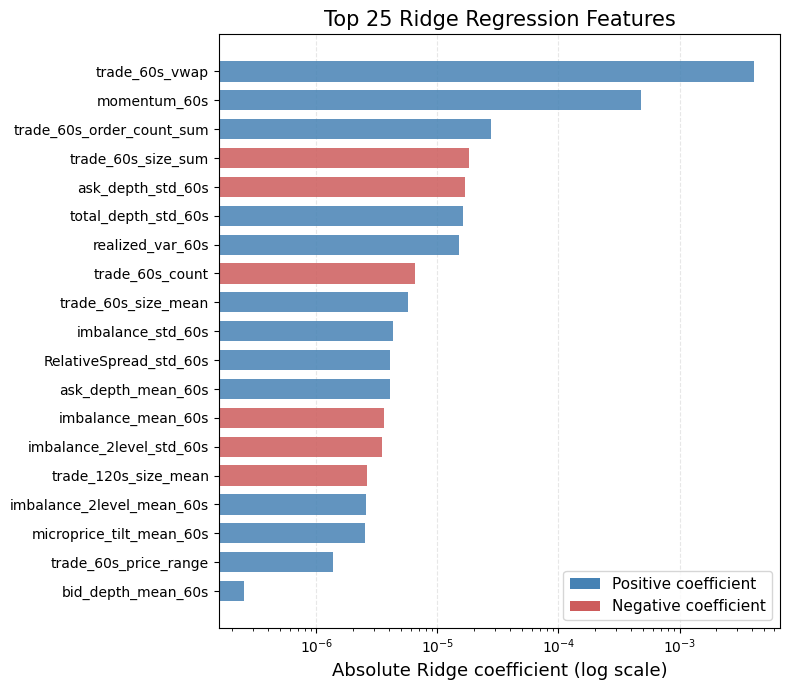

In [26]:
from matplotlib.patches import Patch

# Select top 25 by absolute coefficient
top25 = (
    importance_df
    .head(25)
    .sort_values("Abs_Coefficient", ascending=True)
    .copy()
)

# Log scale cannot display zero values
top25 = top25[top25["Abs_Coefficient"] > 0]

colors = np.where(
    top25["Coefficient"] >= 0,
    "steelblue",
    "indianred"
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.barh(
    top25["Feature"],
    top25["Abs_Coefficient"],
    color=colors,
    height=0.7,
    alpha=0.85
)

ax.set_xscale("log")

ax.set_xlabel("Absolute Ridge coefficient (log scale)", fontsize=13)
ax.set_title("Top 25 Ridge Regression Features", fontsize=15)

ax.tick_params(axis="both", labelsize=10)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor="steelblue", label="Positive coefficient"),
    Patch(facecolor="indianred", label="Negative coefficient")
]

ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=11,
    frameon=True
)

plt.tight_layout()
plt.show()

Generating OOF predictions: Mean Baseline
Generating OOF predictions: Ridge Regression_alpha1


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.2s finished


Generating OOF predictions: Elastic Net


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:   16.6s finished


Generating OOF predictions: XGBoost


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:   13.8s finished
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:16:58] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:16:58] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:17:12] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:17:12] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any ava


First five OOF predictions:
     Actual  Mean Baseline  Ridge Regression_alpha1  Elastic Net       XGBoost
0 -0.000226      -0.000002             1.573086e-06    -0.000002 -7.647741e-07
1  0.000072      -0.000002            -2.923359e-05    -0.000002 -1.010113e-05
2 -0.000579      -0.000003            -7.792707e-06    -0.000003 -5.585464e-06
3  0.000490      -0.000004             5.480891e-07    -0.000004 -7.488357e-06
4 -0.000053      -0.000005             1.494002e-05    -0.000005 -1.120957e-05

OOF performance comparison:
                  Model     RMSE      MAE
          Mean Baseline 0.001065 0.000657
            Elastic Net 0.001065 0.000657
Ridge Regression_alpha1 0.001065 0.000658
                XGBoost 0.001069 0.000659


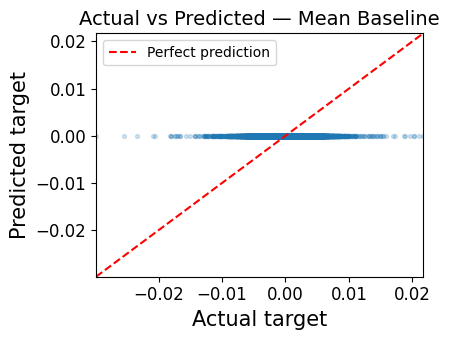

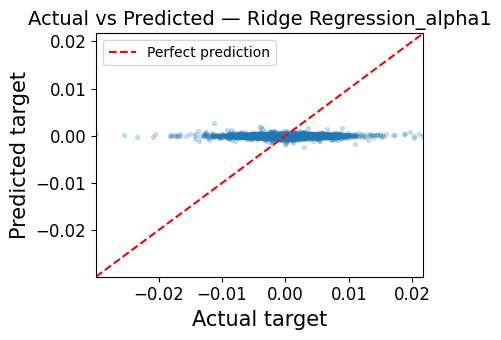

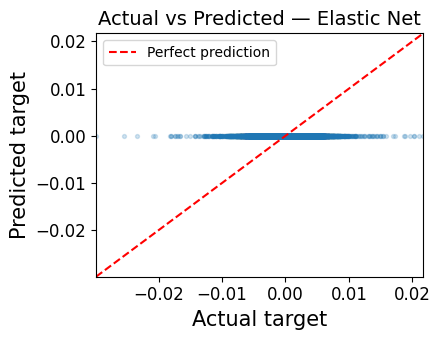

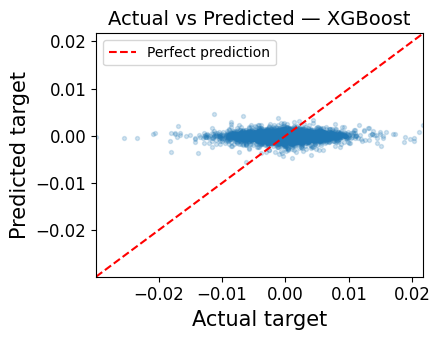

In [39]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

# 1. Generate out-of-fold predictions for every model
oof_predictions = pd.DataFrame({
    "Actual": np.asarray(y_train)
})

for name, model in models.items():

    print(f"Generating OOF predictions: {name}", flush=True)

    oof_predictions[name] = cross_val_predict(
        estimator=model,
        X=X_train_model,
        y=y_train,
        groups=groups,
        cv=cv,
        n_jobs=1,
        verbose=2
    )

# 2. Display the predictions
print("\nFirst five OOF predictions:")
print(oof_predictions.head())

# 3. Calculate overall OOF RMSE and MAE for every model
results = []

for name in models.keys():

    actual = oof_predictions["Actual"]
    predicted = oof_predictions[name]

    results.append({
        "Model": name,
        "RMSE": root_mean_squared_error(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted)
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\nOOF performance comparison:")
print(results_df.to_string(index=False))

# 4. Use common axis limits for fair visual comparison
all_values = oof_predictions[
    ["Actual"] + list(models.keys())
].to_numpy()

low = np.nanmin(all_values)
high = np.nanmax(all_values)

# 5. Plot Actual vs Predicted for every model
actual = oof_predictions["Actual"]

for model_name in models.keys():

    predicted = oof_predictions[model_name]

    plt.figure(figsize=(4.5, 3.5))

    plt.scatter(
        actual,
        predicted,
        alpha=0.2,
        s=8
    )

    # Perfect prediction line
    plt.plot(
        [low, high],
        [low, high],
        "--",
        color="red",
        label="Perfect prediction"
    )

    plt.xlim(low, high)
    plt.ylim(low, high)

    plt.xlabel("Actual target", fontsize=15)
    plt.ylabel("Predicted target", fontsize=15)
    plt.title(f"Actual vs Predicted — {model_name}", fontsize=14)

    plt.tick_params(axis="both", labelsize=12)
    plt.legend(fontsize=11)

    plt.legend()
    plt.tight_layout()
    plt.show()

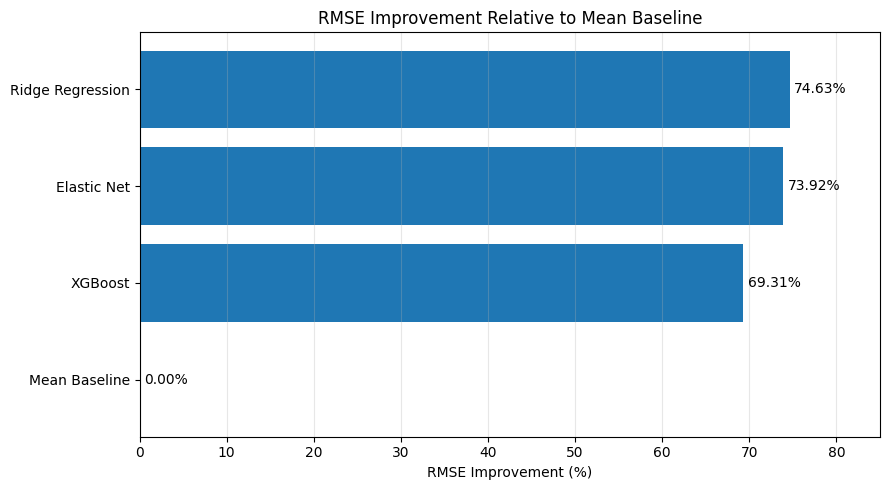

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

results_df = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Elastic Net",
        "XGBoost",
        "Mean Baseline"
    ],
    "RMSE": [0.001117, 0.001148, 0.001351, 0.004402]
})

baseline_rmse = results_df.loc[
    results_df["Model"] == "Mean Baseline", "RMSE"
].iloc[0]

results_df["RMSE_Improvement_%"] = (
    (baseline_rmse - results_df["RMSE"]) / baseline_rmse
) * 100

# Plot
plot_df = results_df.sort_values("RMSE_Improvement_%")

plt.figure(figsize=(9, 5))
bars = plt.barh(
    plot_df["Model"],
    plot_df["RMSE_Improvement_%"]
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height()/2,
        f"{width:.2f}%",
        va="center"
    )

plt.xlabel("RMSE Improvement (%)")
plt.title("RMSE Improvement Relative to Mean Baseline")
plt.xlim(0, 85)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Number of predictions: 85765
First 10 predictions: [1.00387352 0.99864696 0.99552316 1.00539089 0.99862383 0.99772041
 0.99883289 0.99929085 1.00870507 0.99895194]
RMSE: 0.0011295656014087235
MAE: 0.0007118542101943736
R²: 0.9373969518255356


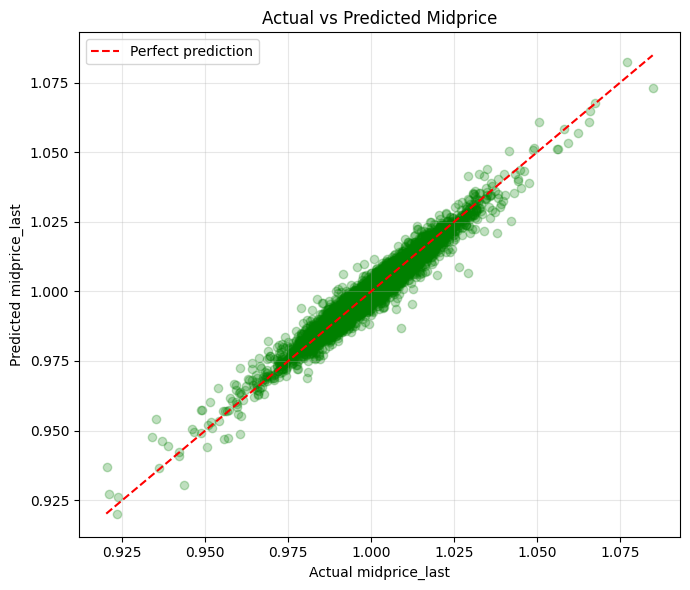

In [32]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Train the model
ridge_model.fit(X_train_model, y_train)

# Predict on the test set
y_pred = ridge_model.predict(X_test_model)

print("Number of predictions:", len(y_pred))
print("First 10 predictions:", y_pred[:10])

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, color="green", alpha=0.25)

# Perfect prediction line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual midprice_last")
plt.ylabel("Predicted midprice_last")
plt.title("Actual vs Predicted Midprice")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



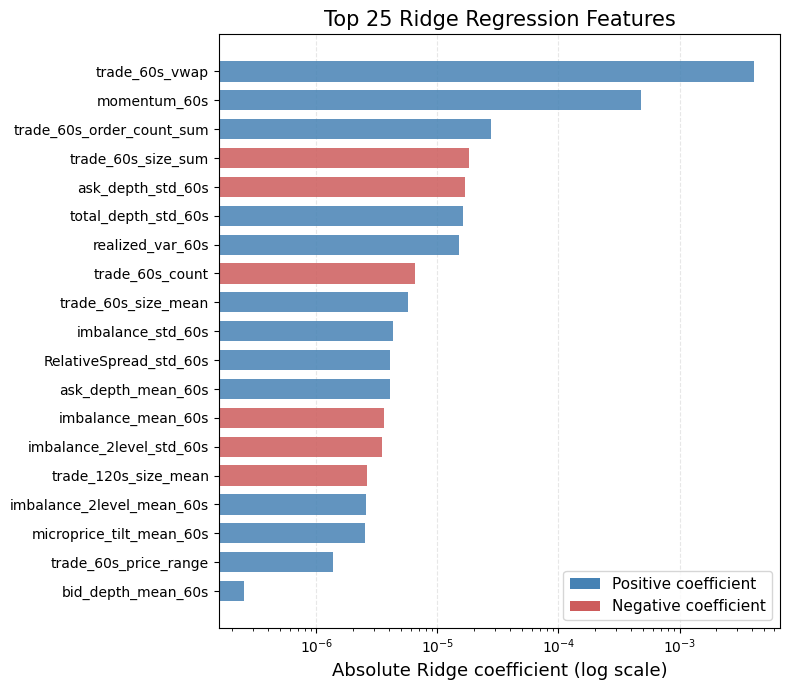

In [35]:
# Extract coefficients from the fitted Ridge model
coefficients = ridge_model.named_steps["ridge"].coef_

# Create coefficient importance DataFrame
importance_df = pd.DataFrame({
    "Feature": X_train_model.columns,
    "Coefficient": coefficients,
    "Abs_Coefficient": np.abs(coefficients)
})

# Select top 25 features by absolute coefficient
top25 = (
    importance_df
    .sort_values("Abs_Coefficient", ascending=False)
    .head(25)
    .sort_values("Abs_Coefficient", ascending=True)
    .copy()
)

# Remove zero coefficients (log scale cannot display zero)
top25 = top25[top25["Abs_Coefficient"] > 0]

# Positive and negative coefficient colours
colors = np.where(
    top25["Coefficient"] >= 0,
    "steelblue",
    "indianred"
)

from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(8, 7))

ax.barh(
    top25["Feature"],
    top25["Abs_Coefficient"],
    color=colors,
    height=0.7,
    alpha=0.85
)

ax.set_xscale("log")

ax.set_xlabel("Absolute Ridge coefficient (log scale)", fontsize=13)
ax.set_title("Top 25 Ridge Regression Features", fontsize=15)

ax.tick_params(axis="both", labelsize=10)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor="steelblue", label="Positive coefficient"),
    Patch(facecolor="indianred", label="Negative coefficient")
]

ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=11,
    frameon=True
)

plt.tight_layout()
plt.show()

In [ ]:
ridge_model = models["Ridge Regression_alpha1"]
ridge_model.fit(X_train_model, y_train)

coefficients = ridge_model.named_steps["ridge"].coef_

importance_df = pd.DataFrame({
    "Feature": X_train_model.columns,
    "Coefficient": coefficients,
    "Abs_Coefficient": np.abs(coefficients)
})

# Sort by absolute coefficient, largest first
importance_df = importance_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

# Display the 20 most important features
print("\nTop 20 features in Ridge Regression:")
print(importance_df.head(25).round(6).to_string(index=False))

### Francis

## Modeling: predicting the change in the bid-ask spread

**Goal.** For every stock in a 10-minute window, use only the first 5 minutes of book data to predict

$$y = \log\left(\frac{S_2}{S_1}\right), \qquad S_h = \frac{1}{T_h}\int_h \frac{a_t - b_t}{m_t}\,dt,$$

the log ratio of the **time-weighted average relative quoted spread** in the second half (seconds 300–599) to that in the first half (seconds 0–299).

**Choices.**
- *Time-weighted*: each book snapshot holds until the next one. Snapshots arrive when the book changes, so a plain average over rows would over-weight busy periods.
- *Relative spread*: dividing by the mid price makes spreads comparable across stocks.
- *Log ratio*: the target is symmetric and tame, while the raw ratio is skewed.

**Approach.** Fit one model shared across stocks (one row per stock and window), adding features that summarize all stocks in the same window. The other stocks' data enters as inputs to a shared model rather than through a huge multi-output model. Evaluate with **10-fold `GroupKFold` on `time_id`**, so a whole window is always in the same fold. Errors are strongly correlated within a window, so a random row split would leak information.

These models use **book data only**, so they run on every stock with book data, not just `AVAILABLE_STOCKS`.bold text

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def missing_stocks(folder):
    """Stocks in train.csv with no book/trade parquet under folder."""
    stock_ids = pd.read_csv(folder / "train.csv", usecols=["stock_id"]).stock_id.unique()
    def has_data(kind, stock_id):
        part = folder / f"{kind}_train.parquet" / f"stock_id={stock_id}"
        return any(p.stat().st_size > 0 for p in part.rglob("*.parquet"))
    return {kind: [int(s) for s in stock_ids if not has_data(kind, s)] for kind in ["book", "trade"]}

missing = missing_stocks(DATA_DIR)
all_stocks = pd.read_csv(DATA_DIR / "train.csv", usecols=["stock_id"]).stock_id.unique()
AVAILABLE_STOCKS = sorted(int(s) for s in all_stocks
                          if s not in missing["book"] and s not in missing["trade"])
print(f"{len(AVAILABLE_STOCKS)} stocks with full data; missing: {missing}")

BOOK_STOCKS = sorted(int(s) for s in all_stocks if s not in missing["book"])
print(f"{len(BOOK_STOCKS)} stocks with book data")

112 stocks with full data; missing: {'book': [], 'trade': []}
112 stocks with book data


### Features from the first half

Each stock's book goes onto a dense `(window × 600 seconds)` grid with forward-fill, so plain means over the grid are time-weighted averages. The target is a ratio, so most features describe where the spread sits *now* relative to its first-half average, and what is pushing it:

| Group | Features |
|---|---|
| Level | `log_S1` (and, per fold, `abn` = `log_S1` minus the stock's typical value) |
| Trend within the half | spread over the last 60/30/10 s and at second 299 relative to $S_1$; first 60 s; dispersion of log spread |
| Tick constraint | average spread in multiples of the minimum spread (≈ ticks); fraction of time at the minimum; relative tick size |
| Volatility & activity | realized volatility of the weighted average price (WAP) over the half and the last 100 s; their ratio; absolute return; number of book updates |
| Depth & shape | level-1/level-2 sizes and recent change; order imbalance; level-2 spread relative to $S_1$ |

`y_skip30` is an alternative target that drops the first 30 s of the second half. It's used in 4.5 to check whether the score comes from the carry-over at the 300 s boundary.

In [ ]:
H = 300  # half-window length in seconds
BOOK_COLS = ["bid_price1", "ask_price1", "bid_price2", "ask_price2",
             "bid_size1", "ask_size1", "bid_size2", "ask_size2"]


def dense_book(book):
    # time_ids and dict of [n_windows, 600] forward-filled arrays (+ 'upd' = 1 where a snapshot arrived)
    tids = np.sort(book.time_id.unique())
    row = np.searchsorted(tids, book.time_id.to_numpy())
    col = book.seconds_in_bucket.to_numpy()
    out = {}
    for c in BOOK_COLS:
        a = np.full((len(tids), 600), np.nan)
        a[row, col] = book[c].to_numpy(dtype=float)
        out[c] = pd.DataFrame(a).ffill(axis=1).to_numpy()
    upd = np.zeros((len(tids), 600))
    upd[row, col] = 1
    out["upd"] = upd
    return tids, out


def log_mean(a, lo, hi):
    return np.log(np.nanmean(a[:, lo:hi], axis=1))


def spread_features(stock_id, book):
    tids, d = dense_book(book)
    bp1, ap1, bp2, ap2 = d["bid_price1"], d["ask_price1"], d["bid_price2"], d["ask_price2"]
    bs1, as1, bs2, as2 = d["bid_size1"], d["ask_size1"], d["bid_size2"], d["ask_size2"]
    mid = (ap1 + bp1) / 2
    s = (ap1 - bp1) / mid                      # relative quoted spread
    s2 = (ap2 - bp2) / mid                     # level-2 relative spread
    wap = (bp1 * as1 + ap1 * bs1) / (bs1 + as1)
    r = np.diff(np.log(wap), axis=1, prepend=np.log(wap[:, :1]))  # 1-second log returns

    f = pd.DataFrame({"stock_id": stock_id, "time_id": tids})
    S1 = np.nanmean(s[:, :H], axis=1)
    f["y"] = np.log(np.nanmean(s[:, H:], axis=1) / S1)
    f["y_skip30"] = np.log(np.nanmean(s[:, H + 30:], axis=1) / S1)
    f["log_S1"] = ls1 = np.log(S1)

    # spread trend within the first half, relative to the half average
    f["sp_last60"] = log_mean(s, H - 60, H) - ls1
    f["sp_last30"] = log_mean(s, H - 30, H) - ls1
    f["sp_last10"] = log_mean(s, H - 10, H) - ls1
    f["sp_now"] = np.log(s[:, H - 1]) - ls1
    f["sp_first60"] = log_mean(s, 0, 60) - ls1
    f["sp_logstd"] = np.nanstd(np.log(s[:, :H]), axis=1)

    # tick constraint: absolute spread in multiples of its minimum
    abs_sp = (ap1 - bp1)[:, :H]
    tick = np.nanmin(np.where(abs_sp > 0, abs_sp, np.nan), axis=1)
    f["sp_ticks"] = np.log(np.nanmean(abs_sp, axis=1) / tick)
    f["frac_min_tick"] = np.mean(abs_sp <= tick[:, None] * 1.001, axis=1)
    f["log_rel_tick"] = np.log(tick / mid[:, H - 1])

    # volatility and activity
    f["log_rv"] = np.log(np.sqrt((r[:, 1:H] ** 2).sum(axis=1)) + 1e-8)
    f["log_rv_last100"] = np.log(np.sqrt((r[:, H - 100:H] ** 2).sum(axis=1)) + 1e-8)
    f["rv_ratio"] = f["log_rv_last100"] - f["log_rv"]
    f["abs_ret"] = np.abs(np.log(wap[:, H - 1] / wap[:, 0]))
    n_upd = d["upd"][:, :H].sum(axis=1)
    f["log_nupd"] = np.log(n_upd)
    f["upd_last60"] = np.log(d["upd"][:, H - 60:H].sum(axis=1) + 1) - np.log(n_upd / 5 + 1)

    # depth / shape of the book
    dep1 = bs1 + as1
    f["log_depth1"] = log_mean(dep1, 0, H)
    f["log_depth2"] = log_mean(bs2 + as2, 0, H)
    f["depth1_last60"] = log_mean(dep1, H - 60, H) - f["log_depth1"]
    f["imbalance"] = np.nanmean(np.abs(bs1 - as1)[:, :H] / dep1[:, :H], axis=1)
    f["imb_now"] = ((bs1 - as1) / dep1)[:, H - 1]
    f["sp2_rel"] = log_mean(s2, 0, H) - ls1
    return f


parts = []
for i, sid in enumerate(BOOK_STOCKS):
    parts.append(spread_features(sid, load_stock("book", sid)))
    if (i + 1) % 10 == 0 or i + 1 == len(BOOK_STOCKS):
        print(f"features: {i + 1}/{len(BOOK_STOCKS)} stocks")
spread_feats = pd.concat(parts, ignore_index=True)
print(spread_feats.shape, "| any NaN:", spread_feats.isna().any().any())
spread_feats.describe().T.round(4)

features: 10/112 stocks
features: 20/112 stocks
features: 30/112 stocks
features: 40/112 stocks
features: 50/112 stocks
features: 60/112 stocks
features: 70/112 stocks
features: 80/112 stocks
features: 90/112 stocks
features: 100/112 stocks
features: 110/112 stocks
features: 112/112 stocks
(428932, 26) | any NaN: False


,count,mean,std,min,25%,50%,75%,max
stock_id,428932.0,62.4379,37.1264,0.0000,30.0000,63.0000,96.0000,126.0000
time_id,428932.0,16038.9727,9365.1037,5.0000,7854.0000,15853.0000,23994.0000,32767.0000
y,428932.0,-0.0357,0.1757,-2.3964,-0.1229,-0.0163,0.0547,1.3903
y_skip30,428932.0,-0.0376,0.1829,-2.4709,-0.1286,-0.0171,0.0565,1.4123
log_S1,428932.0,-7.6495,0.8311,-10.5356,-8.2372,-7.6972,-7.1009,-3.9395
sp_last60,428932.0,-0.0300,0.1666,-1.4327,-0.1159,-0.0127,0.0621,0.8840
sp_last30,428932.0,-0.0387,0.2093,-1.6025,-0.1498,-0.0176,0.0793,1.1118
sp_last10,428932.0,-0.0511,0.2643,-2.2348,-0.1940,-0.0253,0.1035,1.5489
sp_now,428932.0,-0.0726,0.3455,-3.5800,-0.2621,-0.0366,0.1365,1.7710
sp_first60,428932.0,0.0096,0.1656,-1.3103,-0.0738,0.0022,0.1016,1.1589


### Train/test split by window

A random 20% of windows (`time_id`s) is held out as the final test set **before** anything looks at the target. The next cells use only the development set `dev`; `test` is for a single final score once model choices are final.

- Split by window, so every stock's row for a held-out window is in `test`. Errors and the market-wide move are shared within a window.
- The seed is fixed, so the split is identical on every run and on the full dataset. Don't change it after seeing test scores.

In [ ]:
TEST_FRAC = 0.2
SPLIT_SEED = 0

tids = np.sort(spread_feats.time_id.unique())
TEST_TIDS = np.random.default_rng(SPLIT_SEED).choice(tids, size=round(TEST_FRAC * len(tids)), replace=False)
is_test = spread_feats.time_id.isin(TEST_TIDS)
dev = spread_feats[~is_test].reset_index(drop=True)
test = spread_feats[is_test].reset_index(drop=True)
print(f"dev:  {dev.time_id.nunique():,} windows, {len(dev):,} rows")
print(f"test: {test.time_id.nunique():,} windows, {len(test):,} rows")

dev:  3,064 windows, 343,144 rows
test: 766 windows, 85,788 rows


### Quick look at the target

Before modeling, three questions:
1. How much of $y$ is **shared by all stocks in a window**? This is the share of variance explained by the window mean.
2. How much is a **fixed stock effect**? This is the share explained by the stock mean.
3. Do the main signals point the same way **for every stock**? If so, one shared model is justified.

In [ ]:
y = spread_feats.y
by_window = spread_feats.groupby("time_id").y.transform("mean")
by_stock = spread_feats.groupby("stock_id").y.transform("mean")
print(f"var(y) = {y.var():.4f}")
print(f"share of variance explained by window mean: {1 - ((y - by_window) ** 2).mean() / y.var():.3f}")
print(f"share of variance explained by stock mean:  {1 - ((y - by_stock) ** 2).mean() / y.var():.3f}")

eda = spread_feats.assign(abn=spread_feats.log_S1 - spread_feats.groupby("stock_id").log_S1.transform("mean"))
signals = ["abn", "sp_last30", "sp_last60", "sp_first60", "log_rv", "rv_ratio", "sp2_rel"]
per_stock_corr = eda.groupby("stock_id")[signals + ["y"]].corr(method="spearman").xs("y", level=1)[signals]
per_stock = eda.groupby("stock_id").agg(y_std=("y", "std"), frac_min_tick=("frac_min_tick", "mean"))
display(per_stock.join(per_stock_corr).round(2).sort_values("frac_min_tick"))
print("Fraction of stocks where each signal has the same sign as its median:")
print((np.sign(per_stock_corr) == np.sign(per_stock_corr.median())).mean().round(2).to_string())

var(y) = 0.0309
share of variance explained by window mean: 0.176
share of variance explained by stock mean:  0.003


,y_std,frac_min_tick,abn,sp_last30,sp_last60,sp_first60,log_rv,rv_ratio,sp2_rel
stock_id,,,,,,,,,
6,0.17,0.01,-0.27,0.20,0.19,-0.06,-0.19,0.15,0.22
23,0.18,0.01,-0.22,0.27,0.27,-0.12,-0.17,0.16,0.24
22,0.18,0.01,-0.28,0.25,0.24,-0.11,-0.22,0.15,0.26
17,0.17,0.01,-0.28,0.24,0.22,-0.11,-0.22,0.15,0.25
62,0.17,0.01,-0.23,0.25,0.23,-0.10,-0.18,0.17,0.23
...,...,...,...,...,...,...,...,...,...
108,0.10,0.94,-0.16,0.29,0.27,-0.09,-0.22,0.14,0.46
41,0.09,0.95,-0.25,0.41,0.34,-0.10,-0.25,0.12,0.52
77,0.05,0.95,-0.11,0.18,0.19,-0.06,-0.14,0.08,0.40


Fraction of stocks where each signal has the same sign as its median:
abn           1.00
sp_last30     1.00
sp_last60     1.00
sp_first60    0.99
log_rv        1.00
rv_ratio      1.00
sp2_rel       1.00


### Models

Each model adds one idea, so the table shows what each idea is worth:

| # | Model | What it tests |
|---|---|---|
| M0 | predict 0 | "no change" |
| M1 | per-stock mean of $y$ | stock-specific drift |
| M2 | OLS on `abn` only | pure mean reversion |
| M3 | ridge, own-stock features | linear model, full first-half profile |
| M4 | ridge + market features | same, plus other stocks in the window |
| M5 | gradient boosting (`HistGradientBoostingRegressor`), own-stock features | nonlinearity / interactions |
| M6 | gradient boosting + market features | both |
| M7 | average of M4 and M6 | ensemble |

**Avoiding leakage.**
- Features that need a stock's typical level (`abn`, `rv_abn`, `nupd_abn`, `depth_abn`) use stock means from the **training folds only**.
- Market features (`mkt_*`) are averages over stocks *in the same window*, built from first-half features only. Folds are grouped by `time_id`, so this never leaks targets.
- `rel_*` features are a stock's value minus the market average.

In [ ]:
OWN = ["log_S1", "sp_last60", "sp_last30", "sp_last10", "sp_now", "sp_first60",
       "sp_logstd", "sp_ticks", "frac_min_tick", "log_rel_tick", "log_rv",
       "log_rv_last100", "rv_ratio", "abs_ret", "log_nupd", "upd_last60",
       "log_depth1", "log_depth2", "depth1_last60", "imbalance", "imb_now", "sp2_rel"]
# feature -> source column; feature = source minus the stock's training-fold mean
ABN = {"abn": "log_S1", "rv_abn": "log_rv", "nupd_abn": "log_nupd", "depth_abn": "log_depth1"}
MKT_SRC = ["abn", "rv_abn", "nupd_abn", "depth_abn", "sp_last60", "sp_last30", "sp_now",
           "sp_first60", "rv_ratio", "upd_last60", "depth1_last60", "sp2_rel"]
OWN_F = OWN + list(ABN)
MKT_F = OWN_F + ["mkt_" + c for c in MKT_SRC] + ["rel_abn", "rel_last60", "mkt_disp_abn"]


def add_fold_features(tr, te):
    out = []
    for d in (tr, te):
        d = d.copy()
        for new, src in ABN.items():
            d[new] = d[src] - d.stock_id.map(tr.groupby("stock_id")[src].mean())
        m = d.groupby("time_id")[MKT_SRC].transform("mean")
        for c in MKT_SRC:
            d["mkt_" + c] = m[c]
        d["rel_abn"] = d.abn - d.mkt_abn
        d["rel_last60"] = d.sp_last60 - d.mkt_sp_last60
        d["mkt_disp_abn"] = d.groupby("time_id").abn.transform("std")
        out.append(d)
    return out


def ridge():
    return make_pipeline(StandardScaler(), Ridge(alpha=10.0))


def hgb():
    # stock_id (first column) is treated as categorical
    return HistGradientBoostingRegressor(
        learning_rate=0.05, max_iter=500, max_leaf_nodes=31, min_samples_leaf=200,
        l2_regularization=1.0, categorical_features=[0], random_state=0)


MODELS = {
    "M0 zero": lambda tr, te: np.zeros(len(te)),
    "M1 stock mean": lambda tr, te: te.stock_id.map(tr.groupby("stock_id").y.mean()).to_numpy(),
    "M2 OLS abn": lambda tr, te: LinearRegression().fit(tr[["abn"]], tr.y).predict(te[["abn"]]),
    "M3 ridge own": lambda tr, te: ridge().fit(tr[OWN_F], tr.y).predict(te[OWN_F]),
    "M4 ridge +mkt": lambda tr, te: ridge().fit(tr[MKT_F], tr.y).predict(te[MKT_F]),
    "M5 HGB own": lambda tr, te: hgb().fit(tr[["stock_id"] + OWN_F], tr.y).predict(te[["stock_id"] + OWN_F]),
    "M6 HGB +mkt": lambda tr, te: hgb().fit(tr[["stock_id"] + MKT_F], tr.y).predict(te[["stock_id"] + MKT_F]),
}
ENSEMBLES = {"M7 avg(M4,M6)": ["M4 ridge +mkt", "M6 HGB +mkt"]}

### 10-fold cross-validation (development set)

Cross-validation runs on `dev` only; the test windows are not touched here. Metrics are computed on the pooled out-of-fold predictions:
- **RMSE** and **R²**, where R² is relative to predicting the overall mean.
- **R² market**: R² of the window-average prediction against the window-average $y$. Can the model predict the market-wide change in liquidity?
- **R² idio**: R² on deviations from the window average. Can the model predict which stocks widen or narrow relative to the others?
- **Within-window IC**: Spearman correlation between prediction and $y$ across stocks within a window, averaged over windows.
- **R² by group**: tick-bound stocks (at the minimum spread more than half the time) against the rest. Tick-bound stocks have a nearly constant spread and can flatter the overall score.

In [ ]:
def within_window_ic(time_id, y, p):
    d = pd.DataFrame({"t": time_id, "y": y, "p": p})
    r = d.groupby("t")[["y", "p"]].rank()
    r = r - r.groupby(d.t).transform("mean")
    num = (r.y * r.p).groupby(d.t).sum()
    den = np.sqrt((r.y ** 2).groupby(d.t).sum() * (r.p ** 2).groupby(d.t).sum())
    return (num / den.replace(0, np.nan)).mean()


def cross_validate(data, target="y", models=MODELS, ensembles=ENSEMBLES, n_splits=10):
    data = data.assign(y=data[target]).reset_index(drop=True)
    names = list(models) + list(ensembles)
    oof = pd.DataFrame(np.nan, index=data.index, columns=names)
    fold_rmse = {n: [] for n in names}
    for k, (tri, tei) in enumerate(GroupKFold(n_splits=n_splits).split(data, groups=data.time_id)):
        tr, te = add_fold_features(data.iloc[tri], data.iloc[tei])
        for n, fit_predict in models.items():
            oof.loc[tei, n] = fit_predict(tr, te)
        for n, members in ensembles.items():
            oof.loc[tei, n] = oof.loc[tei, members].mean(axis=1)
        for n in names:
            fold_rmse[n].append(np.sqrt(((oof.loc[tei, n] - te.y.to_numpy()) ** 2).mean()))
        print(f"fold {k + 1}/{n_splits} done")
    return data, oof, fold_rmse


def evaluate(data, oof, fold_rmse):
    y = data.y.to_numpy()
    t = data.time_id.to_numpy()
    tick_bound = (data.stock_id.map(data.groupby("stock_id").frac_min_tick.mean()) > 0.5).to_numpy()
    y_w = data.groupby("time_id").y.transform("mean").to_numpy()

    def r2(true, pred):
        return 1 - ((true - pred) ** 2).sum() / ((true - true.mean()) ** 2).sum()

    rows = {}
    for n in oof.columns:
        p = oof[n].to_numpy()
        p_w = pd.Series(p).groupby(t).transform("mean").to_numpy()
        win = pd.DataFrame({"y": y, "p": p}).groupby(t).mean()
        rows[n] = {
            "RMSE": np.sqrt(((y - p) ** 2).mean()),
            "RMSE fold sd": np.std(fold_rmse[n]),
            "R2": r2(y, p),
            "R2 market": r2(win.y.to_numpy(), win.p.to_numpy()),
            "R2 idio": 1 - ((y - y_w - (p - p_w)) ** 2).sum() / ((y - y_w) ** 2).sum(),
            "within-window IC": within_window_ic(t, y, p),
            "R2 tick-bound": r2(y[tick_bound], p[tick_bound]),
            "R2 wide-spread": r2(y[~tick_bound], p[~tick_bound]),
        }
    return pd.DataFrame(rows).T


cv_data, oof, fold_rmse = cross_validate(dev)
results = evaluate(cv_data, oof, fold_rmse)
print(f"{cv_data.stock_id.nunique()} stocks, {cv_data.time_id.nunique()} windows, "
      f"{(cv_data.stock_id.map(cv_data.groupby('stock_id').frac_min_tick.mean()) > 0.5).groupby(cv_data.stock_id).first().sum()} tick-bound stocks")
results.round(4)

fold 1/10 done
fold 2/10 done
fold 3/10 done
fold 4/10 done
fold 5/10 done
fold 6/10 done
fold 7/10 done
fold 8/10 done
fold 9/10 done
fold 10/10 done
112 stocks, 3064 windows, 21 tick-bound stocks


,RMSE,RMSE fold sd,R2,R2 market,R2 idio,within-window IC,R2 tick-bound,R2 wide-spread
M0 zero,0.1792,0.0038,-0.0413,-0.2359,0.0000,NaN,-0.0449,-0.0413
M1 stock mean,0.1753,0.0035,0.0027,-0.0004,0.0033,0.0483,0.0095,0.0014
M2 OLS abn,0.1647,0.0023,0.1201,0.3172,0.0783,0.2558,0.2256,0.1069
M3 ridge own,0.1538,0.0018,0.2329,0.5291,0.1701,0.3544,0.4199,0.2100
M4 ridge +mkt,0.1478,0.0016,0.2910,0.7986,0.1834,0.3695,0.4488,0.2717
M5 HGB own,0.1473,0.0017,0.2958,0.6724,0.2159,0.3873,0.6075,0.2578
M6 HGB +mkt,0.1402,0.0013,0.3620,0.8295,0.2629,0.4305,0.6438,0.3278
"M7 avg(M4,M6)",0.1419,0.0014,0.3467,0.8264,0.2449,0.4168,0.5959,0.3163


### Eloise

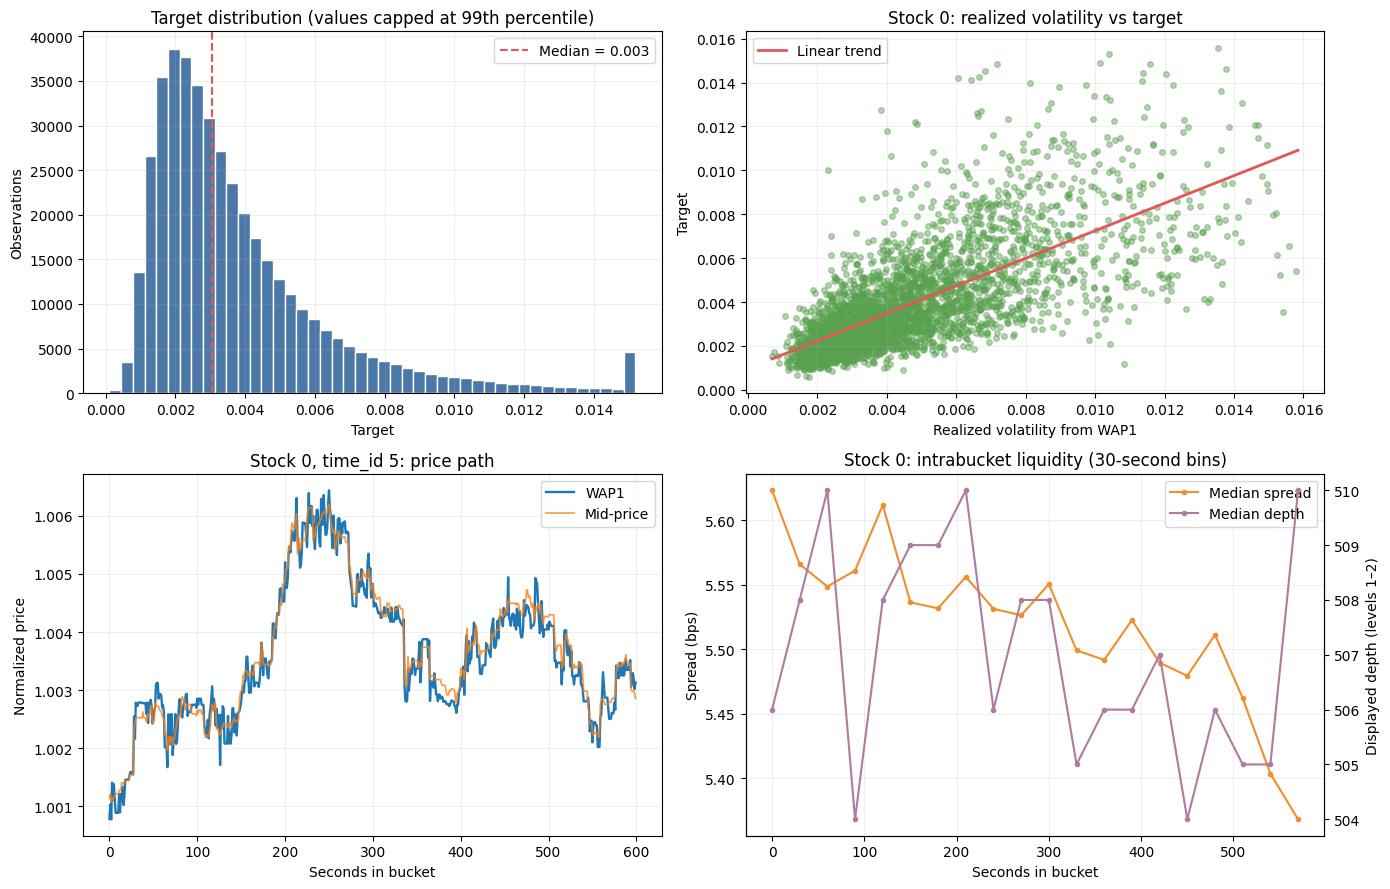

Eloise summary — stock 0
Target skewness (all stocks): 2.82
Correlation between book realized volatility and target: 0.718
Median spread: 5.52 bps
Median displayed depth: 507 shares


,target_summary
count,428932.000000
mean,0.003880
std,0.002936
min,0.000105
1%,0.000800
25%,0.002026
50%,0.003048
75%,0.004738
99%,0.015204
max,0.070321


In [ ]:
# Eloise — target, liquidity, and realized-volatility exploration
# This cell uses the train/book/trades objects created in the setup cells above.

book_eda = book.copy()
book_eda["mid_price"] = (book_eda["bid_price1"] + book_eda["ask_price1"]) / 2
book_eda["wap1"] = (
    book_eda["bid_price1"] * book_eda["ask_size1"]
    + book_eda["ask_price1"] * book_eda["bid_size1"]
) / (book_eda["bid_size1"] + book_eda["ask_size1"])
book_eda["spread_bps"] = (
    (book_eda["ask_price1"] - book_eda["bid_price1"])
    / book_eda["mid_price"] * 10_000
)
book_eda["total_depth"] = (
    book_eda[["bid_size1", "ask_size1", "bid_size2", "ask_size2"]].sum(axis=1)
)
book_eda["log_return"] = book_eda.groupby("time_id")["wap1"].transform(
    lambda s: np.log(s).diff()
)

rv = (book_eda.groupby("time_id")["log_return"]
      .apply(lambda s: np.sqrt(np.square(s.dropna()).sum()))
      .rename("realized_volatility")
      .reset_index())
rv_target = rv.merge(
    train.loc[train["stock_id"] == STOCK_ID, ["time_id", "target"]],
    on="time_id", how="inner"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Target distribution across the full training set (trim only for display).
target_cap = train["target"].quantile(0.99)
axes[0, 0].hist(train["target"].clip(upper=target_cap), bins=45,
                color="#4C78A8", edgecolor="white")
axes[0, 0].axvline(train["target"].median(), color="#E45756", linestyle="--",
                   label=f'Median = {train["target"].median():.3f}')
axes[0, 0].set(title="Target distribution (values capped at 99th percentile)",
               xlabel="Target", ylabel="Observations")
axes[0, 0].legend()

# 2) Does realized volatility from the order book track the target?
x_cap = rv_target["realized_volatility"].quantile(0.99)
y_cap = rv_target["target"].quantile(0.99)
plot_points = rv_target[(rv_target["realized_volatility"] <= x_cap) &
                        (rv_target["target"] <= y_cap)]
axes[0, 1].scatter(plot_points["realized_volatility"], plot_points["target"],
                   s=16, alpha=0.45, color="#59A14F")
if len(plot_points) > 1 and plot_points["realized_volatility"].nunique() > 1:
    slope, intercept = np.polyfit(plot_points["realized_volatility"],
                                  plot_points["target"], 1)
    x_line = np.linspace(plot_points["realized_volatility"].min(), x_cap, 100)
    axes[0, 1].plot(x_line, slope * x_line + intercept, color="#E45756",
                    linewidth=2, label="Linear trend")
axes[0, 1].set(title=f"Stock {STOCK_ID}: realized volatility vs target",
               xlabel="Realized volatility from WAP1", ylabel="Target")
axes[0, 1].legend()

# 3) WAP and midpoint during a representative 10-minute bucket.
sample_time = int(book_eda["time_id"].drop_duplicates().iloc[0])
sample = book_eda[book_eda["time_id"] == sample_time]
axes[1, 0].plot(sample["seconds_in_bucket"], sample["wap1"],
                label="WAP1", linewidth=1.7)
axes[1, 0].plot(sample["seconds_in_bucket"], sample["mid_price"],
                label="Mid-price", linewidth=1.2, alpha=0.8)
axes[1, 0].set(title=f"Stock {STOCK_ID}, time_id {sample_time}: price path",
               xlabel="Seconds in bucket", ylabel="Normalized price")
axes[1, 0].legend()

# 4) Typical liquidity through the 10-minute bucket.
book_eda["second_bin"] = (book_eda["seconds_in_bucket"] // 30) * 30
liquidity_curve = book_eda.groupby("second_bin").agg(
    median_spread_bps=("spread_bps", "median"),
    median_depth=("total_depth", "median")
).reset_index()
ax_depth = axes[1, 1].twinx()
axes[1, 1].plot(liquidity_curve["second_bin"],
                liquidity_curve["median_spread_bps"], color="#F28E2B",
                marker="o", markersize=3, label="Median spread")
ax_depth.plot(liquidity_curve["second_bin"], liquidity_curve["median_depth"],
              color="#B07AA1", marker="o", markersize=3, label="Median depth")
axes[1, 1].set(title=f"Stock {STOCK_ID}: intrabucket liquidity (30-second bins)",
               xlabel="Seconds in bucket", ylabel="Spread (bps)")
ax_depth.set_ylabel("Displayed depth (levels 1–2)")
lines1, labels1 = axes[1, 1].get_legend_handles_labels()
lines2, labels2 = ax_depth.get_legend_handles_labels()
axes[1, 1].legend(lines1 + lines2, labels1 + labels2, loc="best")

for ax in axes.flat:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

correlation = rv_target[["realized_volatility", "target"]].corr().iloc[0, 1]
print(f"Eloise summary — stock {STOCK_ID}")
print(f"Target skewness (all stocks): {train['target'].skew():.2f}")
print(f"Correlation between book realized volatility and target: {correlation:.3f}")
print(f"Median spread: {book_eda['spread_bps'].median():.2f} bps")
print(f"Median displayed depth: {book_eda['total_depth'].median():.0f} shares")
display(train["target"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
        .rename("target_summary").to_frame())

## Bid–ask spread widening events

**Question.** Using only order-book observations from seconds 0–299, can we predict whether the spread will widen during seconds 300–599?

For each stock and 10-minute window, define `spread_bps = (ask_price1 - bid_price1) / midpoint × 10,000`. The continuous outcome is the 90th-percentile spread in the second half divided by the median spread in the first half. The binary event is 1 when this ratio is at least **1.5×**. Using a percentile in the outcome makes the label less sensitive to a single noisy quote; the fixed 1.5× threshold is interpretable and the sensitivity table below shows how class balance changes at nearby thresholds. All predictors are computed strictly before second 300 to prevent leakage.

The validation split holds out entire `time_id` groups so that observations from the same market window cannot appear in both train and test. (`time_id` values are identifiers, not a guaranteed chronological sequence.)

In [ ]:
# Build one leakage-safe row per (stock_id, time_id). This may take a few minutes.
from time import perf_counter

EVENT_RATIO = 1.50

def add_book_features(df):
    df = df.copy()
    df["mid_price"] = (df["bid_price1"] + df["ask_price1"]) / 2
    df["spread_bps"] = (df["ask_price1"] - df["bid_price1"]) / df["mid_price"] * 10_000
    df["depth"] = df[["bid_size1", "ask_size1", "bid_size2", "ask_size2"]].sum(axis=1)
    df["imbalance"] = (df["bid_size1"] - df["ask_size1"]) / (df["bid_size1"] + df["ask_size1"]).replace(0, np.nan)
    df["wap1"] = (df["bid_price1"] * df["ask_size1"] + df["ask_price1"] * df["bid_size1"]) / (df["bid_size1"] + df["ask_size1"]).replace(0, np.nan)
    return df

def summarize_window(group):
    first = group[group["seconds_in_bucket"] < 300].sort_values("seconds_in_bucket")
    second = group[group["seconds_in_bucket"] >= 300]
    if first.empty or second.empty:
        return None
    x = first["seconds_in_bucket"].to_numpy()
    spread = first["spread_bps"].to_numpy()
    slope = np.polyfit(x, spread, 1)[0] if len(first) > 1 and np.ptp(x) > 0 else 0.0
    log_wap = np.log(first["wap1"]).replace([np.inf, -np.inf], np.nan).dropna()
    fh_median = first["spread_bps"].median()
    sh_q90 = second["spread_bps"].quantile(0.90)
    return pd.Series({
        "first_spread_median": fh_median,
        "first_spread_mean": first["spread_bps"].mean(),
        "first_spread_std": first["spread_bps"].std(),
        "first_spread_q90": first["spread_bps"].quantile(0.90),
        "first_spread_max": first["spread_bps"].max(),
        "first_spread_last": first["spread_bps"].iloc[-1],
        "first_spread_slope": slope,
        "first_depth_median": first["depth"].median(),
        "first_depth_q10": first["depth"].quantile(0.10),
        "first_imbalance_mean": first["imbalance"].mean(),
        "first_imbalance_std": first["imbalance"].std(),
        "first_imbalance_last": first["imbalance"].iloc[-1],
        "first_wap_realized_vol": np.sqrt(np.square(log_wap.diff().dropna()).sum()),
        "first_quote_count": len(first),
        "first_seconds_covered": first["seconds_in_bucket"].nunique(),
        "second_spread_q90": sh_q90,
        "widening_ratio": sh_q90 / fh_median if fh_median > 0 else np.nan,
    })

started = perf_counter()
window_rows = []
for stock_id in sorted(train["stock_id"].unique()):
    stock_book = add_book_features(load_stock("book", int(stock_id)))
    stock_summary = stock_book.groupby("time_id", sort=False).apply(summarize_window).dropna(how="all").reset_index()
    stock_summary.insert(0, "stock_id", int(stock_id))
    window_rows.append(stock_summary)

spread_events = pd.concat(window_rows, ignore_index=True)
spread_events = spread_events.replace([np.inf, -np.inf], np.nan).dropna(subset=["widening_ratio"])
spread_events["spread_widening_event"] = (spread_events["widening_ratio"] >= EVENT_RATIO).astype(int)
print(f"Built {len(spread_events):,} windows in {(perf_counter() - started) / 60:.1f} minutes")
display(spread_events.head())

In [ ]:
# EDA: class balance, threshold sensitivity, and cross-stock heterogeneity.
thresholds = [1.25, 1.50, 1.75, 2.00]
sensitivity = pd.DataFrame({
    "widening_ratio_threshold": thresholds,
    "event_prevalence": [(spread_events["widening_ratio"] >= t).mean() for t in thresholds],
})
by_stock = (spread_events.groupby("stock_id")["spread_widening_event"]
            .agg(["mean", "size"]).rename(columns={"mean": "event_rate", "size": "windows"})
            .sort_values("event_rate"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ratio_cap = spread_events["widening_ratio"].quantile(0.99)
axes[0].hist(spread_events["widening_ratio"].clip(upper=ratio_cap), bins=60, color="#4C78A8", edgecolor="white")
axes[0].axvline(EVENT_RATIO, color="#E45756", linestyle="--", label=f"event threshold = {EVENT_RATIO:.2f}×")
axes[0].set(title="Second-half / first-half spread ratio", xlabel="Widening ratio (capped at 99th percentile)", ylabel="Windows")
axes[0].legend()
axes[1].bar(by_stock.index.astype(str), by_stock["event_rate"], color="#59A14F")
axes[1].axhline(spread_events["spread_widening_event"].mean(), color="black", linestyle="--", linewidth=1)
axes[1].set(title="Event rate varies by stock", xlabel="Stock ID", ylabel="Event rate")
axes[1].tick_params(axis="x", labelrotation=90, labelsize=6)
sample_points = spread_events.sample(min(5000, len(spread_events)), random_state=42)
axes[2].scatter(sample_points["first_spread_median"], sample_points["widening_ratio"].clip(upper=ratio_cap), s=8, alpha=0.25, color="#F28E2B")
axes[2].axhline(EVENT_RATIO, color="#E45756", linestyle="--")
axes[2].set(title="Starting liquidity vs future widening", xlabel="First-half median spread (bps)", ylabel="Widening ratio")
for ax in axes: ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Chosen event prevalence: {spread_events['spread_widening_event'].mean():.1%}")
display(sensitivity.style.format({"event_prevalence": "{:.1%}"}))
display(by_stock.describe().T)

In [ ]:
# Grouped baseline: hold out complete time_id groups and score the rare-event ranking.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

target_col = "spread_widening_event"
leakage_cols = {target_col, "second_spread_q90", "widening_ratio", "time_id"}
feature_cols = [c for c in spread_events.columns if c not in leakage_cols]
X = spread_events[feature_cols]
y = spread_events[target_col]
groups = spread_events["time_id"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
numeric_cols = [c for c in feature_cols if c != "stock_id"]
preprocess = ColumnTransformer([
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("scale", StandardScaler())]), numeric_cols),
    ("stock", OneHotEncoder(handle_unknown="ignore"), ["stock_id"]),
])
model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
model.fit(X.iloc[train_idx], y.iloc[train_idx])
probability = model.predict_proba(X.iloc[test_idx])[:, 1]
prediction = (probability >= 0.50).astype(int)

print(f"Train windows: {len(train_idx):,}; test windows: {len(test_idx):,}")
print(f"Train prevalence: {y.iloc[train_idx].mean():.1%}; test prevalence: {y.iloc[test_idx].mean():.1%}")
print(f"ROC AUC: {roc_auc_score(y.iloc[test_idx], probability):.3f}")
print(f"Average precision: {average_precision_score(y.iloc[test_idx], probability):.3f} (no-skill baseline = {y.iloc[test_idx].mean():.3f})")
print(classification_report(y.iloc[test_idx], prediction, digits=3, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y.iloc[test_idx], prediction), display_labels=["no widening", "widening"]).plot(cmap="Blues")
plt.title("Grouped holdout confusion matrix at threshold 0.50")
plt.show()

coef = model.named_steps["classifier"].coef_[0]
names = model.named_steps["preprocess"].get_feature_names_out()
importance = pd.Series(coef, index=names).sort_values()
display(pd.concat([importance.head(10), importance.tail(10)]).rename("logistic_coefficient").to_frame())